2026.10.24(토)/25(일) 주말에 '강사님' 파일 책 읽듯이 읽고 코드 실행시키며 STFT 꼭 이해하고 오기 -> 다음주 월요일 mel, 음성모델 수업 이해 가능함

# 2026.10.22(목) 22h~

In [1]:
import numpy as np                         # 숫자 배열을 계산하는 도구
import matplotlib.pyplot as plt            # 숫자를 그래프로 보는 도구
from IPython.display import Audio, display # 노트북 안에 재생 버튼을 표시하는 도구
from pathlib import Path                   # 파일 위치를 표현하는 도구
import json                                # 작은 결과 기록을 저장하는 도구
import matplotlib.font_manager as fm

# 그래프에 한글을 표시합니다. 이 준비 코드는 수정하지 않고 실행합니다.
available_fonts = {font.name for font in fm.fontManager.ttflist}
for font_name in ["Malgun Gothic", "AppleGothic", "NanumGothic", "Noto Sans CJK KR"]:
    if font_name in available_fonts:
        plt.rcParams["font.family"] = font_name
        break
plt.rcParams["axes.unicode_minus"] = False
plt.rcParams["figure.figsize"] = (10, 3)
plt.rcParams["figure.dpi"] = 110

SR = 16000  # 이번 기초 실습의 기준: 1초에 16,000개. 모든 모델의 공통 규격이라는 뜻은 아닙니다.
print("준비 완료 / 이번 실습의 SR:", SR)

준비 완료 / 이번 실습의 SR: 16000


In [2]:
from scipy.io import wavfile

def read_pcm16(path):
    """PCM16 파일 → (샘플링레이트, 계산용 실수 배열). 채널은 그대로 둡니다."""
    sr, integers = wavfile.read(path)
    if integers.dtype != np.int16:
        raise ValueError("이번 실습에는 16비트 정수 PCM WAV를 사용하세요.")
    if sr <= 0 or integers.size == 0:
        raise ValueError("SR이 올바르고 샘플이 들어 있는 WAV가 필요합니다.")
    if integers.ndim not in (1, 2):
        raise ValueError("모노 또는 채널 축이 있는 WAV가 필요합니다.")
    sound = integers.astype(np.float32) / 32768.0  # 정수 → 실수 → 크기 눈금 변환
    return int(sr), sound

DATA_DIR = Path("data")
DATA_DIR.mkdir(exist_ok=True)
sample_path = DATA_DIR / "tone_sequence_16k_mono.wav"
if not sample_path.exists():
    # 2초 예제: 0.20~0.80초 440Hz, 1.00~1.60초 880Hz, 나머지는 무음
    sample_times = np.arange(2 * SR) / SR
    generated = np.zeros(2 * SR, dtype=np.float32)
    for start, end, hz in [(0.20, 0.80, 440), (1.00, 1.60, 880)]:
        mask = (sample_times >= start) & (sample_times < end)
        generated[mask] = 0.35 * np.sin(2 * np.pi * hz * sample_times[mask])
    wavfile.write(sample_path, SR, np.round(generated * 32767).astype(np.int16))
    print("예제 합성음 생성:", sample_path)

In [3]:
sr, audio = read_pcm16(sample_path)
print("공통 파일:", sample_path.name, "/", sr, "Hz /", len(audio) / sr, "초")
display(Audio(audio, rate=sr, normalize=False))

공통 파일: tone_sequence_16k_mono.wav / 16000 Hz / 2.0 초


## 실습1. 전체 주파수 보기

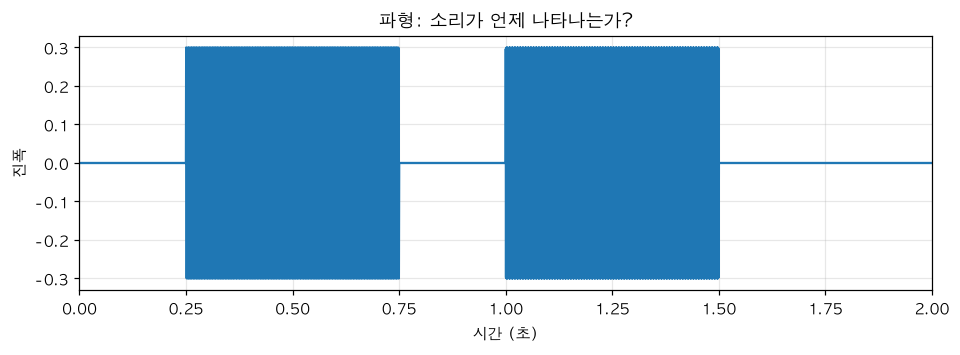

In [4]:
time = np.arange(len(audio)) / sr
plt.figure()
plt.plot(time, audio)
plt.xlabel("시간 (초)")
plt.ylabel("진폭")
plt.title("파형: 소리가 언제 나타나는가?")
plt.xlim(0, 2)
plt.grid(alpha=0.3)
plt.show()

In [17]:
# TODO 강사님 수업 자료에는 이 사이에 주파수 다른 두 소리 파동 그래프 있는 것 같은데..?

## 실습2. FFT?

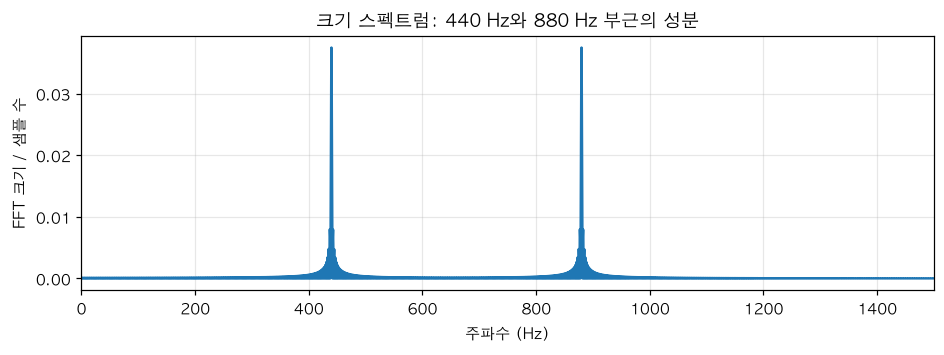

In [ ]:
# 1. 음성 신호를 FFT로 변환 -> fft_result는 크기 및 위상을 가짐
# 시간 영역의 음성 데이터를 주파수 영역으로 변환합니다.
# rfft()는 실수 신호에서 중복되는 음의 주파수 영역을 생략합니다.
fft_result = np.fft.rfft(audio)

# 2. 각 주파수 성분의 크기 계산
# FFT 결과는 복소수이므로 abs()로 크기(Magnitude)를 구합니다.
# 샘플 수로 나누어 신호 길이에 따른 크기 차이를 일부 보정합니다.
fft_size = np.abs(fft_result) / len(audio)

# 3. FFT 결과에 대응하는 주파수 계산
# 각 FFT 결과가 몇 Hz에 해당하는지 구합니다.
# d는 샘플 하나를 측정하는 시간 간격(1 / sr)입니다.
frequency_axis = np.fft.rfftfreq(len(audio), d=1 / sr)

# 4. 주파수별 크기를 그래프로 표시
plt.figure()
plt.plot(frequency_axis, fft_size)

plt.xlabel("주파수 (Hz)")          # X축: 주파수
plt.ylabel("FFT 크기 / 샘플 수")    # Y축: 주파수 성분의 크기
plt.title("크기 스펙트럼: 440 Hz와 880 Hz 부근의 성분")

plt.xlim(0, 1500)                  # 0~1500Hz 범위만 표시
plt.grid(alpha=0.3)                # 그래프에 보조 눈금 표시
plt.show()

### Q. "전체 음성을 주파수별로 분석하여 복소수 배열을 반환합니다"는 무슨 뜻인가? (그림으로 단계별 설명)

**먼저 질문에 대한 답:** 네, 맞습니다. **여러 소리가 섞인 복합 음성이 "어떤 주파수의 소리들로 이루어져 있는지"를 분해해서 알아내는 것**이 FFT입니다. 아래 그림과 숫자는 바로 아래 코드 셀을 실행한 결과이고, 직접 실행해서 확인했습니다.

#### 1. 주파수가 뭔가요? — "1초에 몇 번 오르내리나"
- **주파수(Hz) = 파형이 1초 동안 위아래로 몇 번 반복하는가.** 3 Hz는 1초에 3번, 14 Hz는 1초에 14번입니다.
- 소리로 들으면 **주파수가 클수록 높은 음, 작을수록 낮은 음**입니다(앞 수업의 도~솔 예: 도 262 Hz, 솔 392 Hz. 880 Hz는 440 Hz보다 한 옥타브 위).
- 아래 그림 ①을 보세요. 맨 위 파란 선(3 Hz)은 1초 동안 봉우리가 3번, 초록 선(14 Hz)은 14번 나옵니다.

#### 2. 복합 음성이 뭔가요? — "여러 사인파를 더한 것"
- 실제 소리는 보통 **여러 주파수의 사인파가 동시에** 섞여 있습니다. 악기 소리, 사람 목소리 모두 그렇습니다.
- 마이크는 섞인 결과 **한 줄의 파형만** 기록합니다. 그림 ②가 그것입니다: ①의 세 선을 **같은 시각끼리 더한** 모양입니다(예: 시각 0.1초의 값 = 3 Hz 값 + 8 Hz 값 + 14 Hz 값). 섞이고 나면 눈으로는 "무엇이 섞였는지" 알아보기 어렵습니다.

#### 3. FFT가 하는 일 — 그림 ② → ③
- **FFT는 ②(합쳐진 파형 하나)만 보고, ①의 재료(어떤 주파수가 얼마나)를 거꾸로 알아냅니다.** 그 결과가 그림 ③입니다.
- ③에서 막대가 **3 Hz, 8 Hz, 14 Hz에만** 서 있습니다. 우리가 섞은 재료 그대로입니다. 막대 높이는 크기(3 Hz가 가장 큼, 진폭 1.0 → 0.5)의 순서도 맞습니다.
- 비유: **프리즘**이 흰 빛을 무지개 색으로 나누듯이, FFT는 섞인 소리를 **주파수로 나눠 줍니다.** (비유이며 수학적으로 똑같다는 뜻은 아닙니다.)
- 이 "나눈다"는 수학적으로 항상 가능합니다(어떤 소리든 사인파들의 합으로 쓸 수 있음). 푸리에의 아이디어로 알려져 있으며 이 노트북에서 증명하지는 않습니다(일반 지식).


주파수(Hz) | 크기 | 크기×2
       3   | 0.500 | 1.000
       8   | 0.250 | 0.500
      14   | 0.125 | 0.250

후보 주파수 | 합쳐진 소리 × 후보 사인파 → 평균 ×2
       1 Hz |  0.000
       2 Hz |  0.000
       3 Hz |  1.000
       4 Hz |  0.000
       5 Hz |  0.000
       8 Hz |  0.500
      11 Hz |  0.000
      14 Hz |  0.250


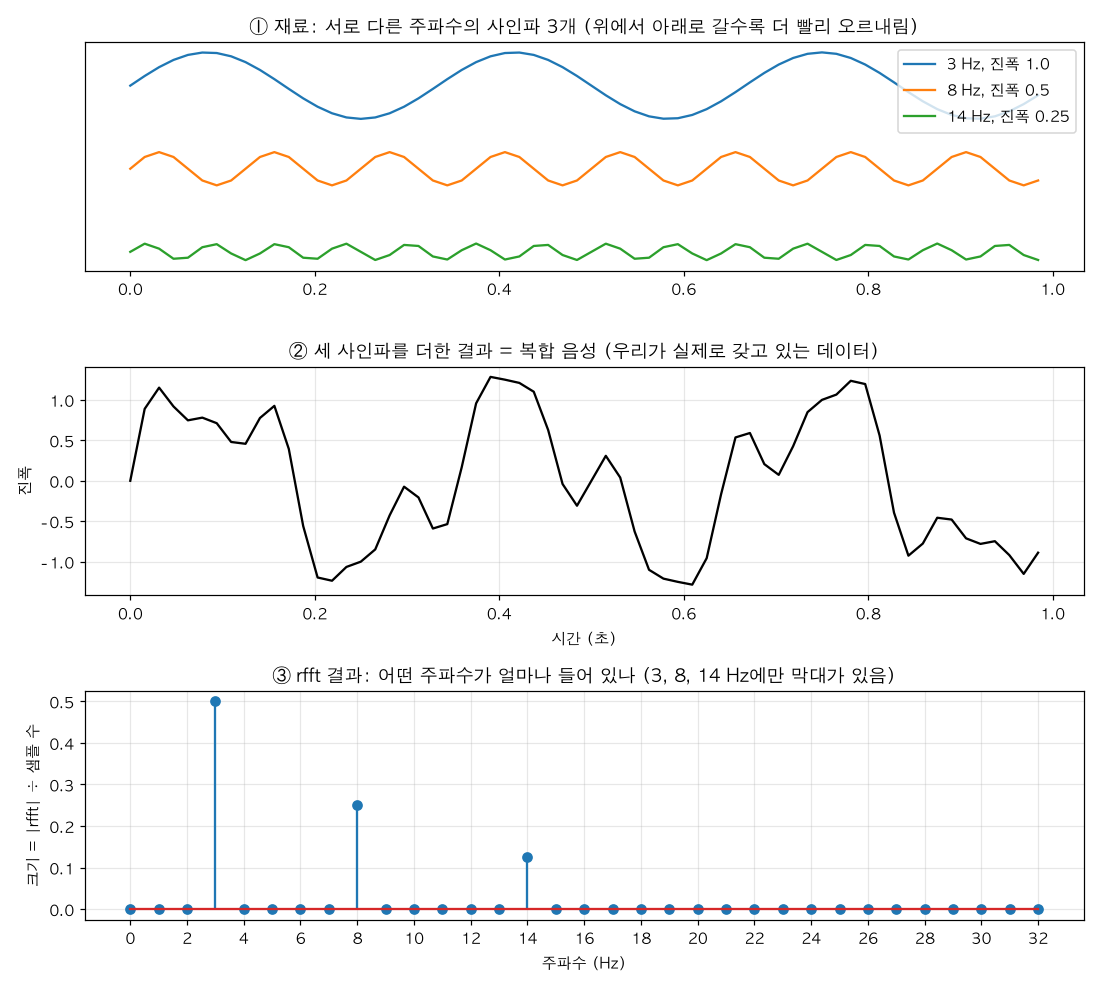

In [ ]:
# "음성을 주파수별로 분석한다"를 눈으로 보는 예제
# 소리 3개(3Hz, 8Hz, 14Hz 사인파)를 더해서 '복합 음성'을 만들고, rfft로 다시 분해해 봅니다.
import numpy as np
import matplotlib.pyplot as plt

sr = 64                    # 1초에 64번 측정 (그림이 잘 보이도록 작은 값을 사용)
t = np.arange(sr) / sr     # 0, 1/64, 2/64, ... 63/64초 → 샘플 64개, 전체 1초

# (주파수 Hz, 진폭)  : 1초에 3번 / 8번 / 14번 오르내리는 사인파 3개
parts = [(3, 1.0), (8, 0.5), (14, 0.25)]
waves = [a * np.sin(2 * np.pi * f * t) for f, a in parts]

# 복합 음성 = 세 사인파를 같은 시각끼리 더한 것 (마이크는 이 합쳐진 모양 하나만 기록합니다)
mixed = waves[0] + waves[1] + waves[2]

# FFT: 합쳐진 파형 하나만 보고, 어떤 주파수가 얼마나 들어 있는지 거꾸로 찾아냅니다.
fft_result = np.fft.rfft(mixed)                    # 칸마다 복소수 1개 (샘플 64개 → 64÷2+1 = 33칸)
fft_size = np.abs(fft_result) / len(mixed)         # 칸마다 크기
freqs = np.fft.rfftfreq(len(mixed), d=1 / sr)      # 칸마다 주파수(Hz): 0, 1, 2, ..., 32

fig, axes = plt.subplots(3, 1, figsize=(10, 9))

# ① 재료: 사인파 3개 (세로로 간격을 띄워서 겹치지 않게 그림)
for k, ((f, a), w) in enumerate(zip(parts, waves)):
    axes[0].plot(t, w + (2 - k) * 2.5, label=f"{f} Hz, 진폭 {a}")
axes[0].set_title("① 재료: 서로 다른 주파수의 사인파 3개 (위에서 아래로 갈수록 더 빨리 오르내림)")
axes[0].set_yticks([])
axes[0].legend(loc="upper right")

# ② 합친 결과: 이것이 '복합 음성' (소리를 녹음하면 이 모양 하나만 남음)
axes[1].plot(t, mixed, color="black")
axes[1].set_title("② 세 사인파를 더한 결과 = 복합 음성 (우리가 실제로 갖고 있는 데이터)")
axes[1].set_xlabel("시간 (초)")
axes[1].set_ylabel("진폭")
axes[1].grid(alpha=0.3)

# ③ FFT 결과: 합쳐진 모양에서 주파수별 크기를 되찾음
axes[2].stem(freqs, fft_size)
axes[2].set_title("③ rfft 결과: 어떤 주파수가 얼마나 들어 있나 (3, 8, 14 Hz에만 막대가 있음)")
axes[2].set_xlabel("주파수 (Hz)")
axes[2].set_ylabel("크기 = |rfft| ÷ 샘플 수")
axes[2].set_xticks(range(0, 33, 2))
axes[2].grid(alpha=0.3)
plt.tight_layout()
plt.show()

# 막대가 있는 칸만 출력: 주파수, 크기, 크기 × 2 (= 원래 사인파의 진폭)
print("주파수(Hz) | 크기 | 크기×2")
for f, s in zip(freqs, fft_size):
    if s > 0.01:
        print(f"{f:8.0f}   | {s:.3f} | {2 * s:.3f}")

# 'FFT가 하는 일'을 손으로 해 보기: 후보 주파수 사인파를 곱해서 더해 본다 (같은 주파수일 때만 큼)
print("\n후보 주파수 | 합쳐진 소리 × 후보 사인파 → 평균 ×2")
for f in [1, 2, 3, 4, 5, 8, 11, 14]:
    score = np.sum(mixed * np.sin(2 * np.pi * f * t)) * 2 / len(t)
    score = round(score, 6) + 0.0                   # -0.000 대신 0.000으로 보이게 정리
    print(f"{f:8d} Hz | {score:6.3f}")


#### 4. 문장을 쪼개서 읽기: "전체 음성을 주파수별로 분석하여 복소수 배열을 반환합니다"
| 문장의 조각 | 이 예제에서의 뜻 |
|---|---|
| **전체 음성을** | 샘플 64개 전부(1초 전체)를 한꺼번에 입력으로 쓴다 (`rfft(mixed)`의 `mixed`) |
| **주파수별로** | 0 Hz, 1 Hz, 2 Hz, … 32 Hz **칸마다 따로** 본다 (`freqs`가 그 칸들의 이름표, 33칸) |
| **분석하여** | 각 칸에 대해 "이 주파수의 사인파가 합쳐진 소리 안에 **얼마나, 어떤 타이밍으로** 들어 있나"를 계산한다 |
| **복소수 배열을 반환** | 칸마다 숫자 1개씩, 모두 33개를 담은 NumPy 배열을 돌려준다 (`fft_result`). 숫자 하나가 "크기 + 시작 위치" 두 정보를 함께 담은 **복소수** |

#### 5. 어떻게 알아내나? — "후보 사인파를 대어 보기" (손으로 해 보기)
FFT를 이해하는 가장 쉬운 방법입니다(계산 원리의 직관이며, 실제 FFT는 이를 빠르게 계산하는 방법입니다).
1. **후보 주파수**(예: 3 Hz)의 사인파를 하나 준비합니다.
2. 합쳐진 소리와 그 사인파를 **같은 시각끼리 곱해서 전부 더합니다.**
3. 합쳐진 소리 안에 **같은 주파수가 있으면** 곱한 값이 계속 같은 부호로 쌓여 **큰 값**이 되고, **없으면** + 와 − 가 서로 상쇄돼 **거의 0**이 됩니다.
4. 후보를 0 Hz, 1 Hz, 2 Hz, …로 바꿔 가며 반복합니다. → 칸마다 하나씩 값이 나옵니다.

코드 셀 마지막 출력이 실제로 이렇게 나왔습니다.

| 후보 주파수 | 1 | 2 | **3** | 4 | 5 | **8** | 11 | **14** |
|---|---|---|---|---|---|---|---|---|
| 곱해서 더한 값(평균 ×2) | 0 | 0 | **1.0** | 0 | 0 | **0.5** | 0 | **0.25** |

- 정확히 **섞은 재료(3 Hz 진폭 1.0, 8 Hz 0.5, 14 Hz 0.25)** 의 진폭이 나옵니다. 재료에 없는 주파수는 0입니다.
- **한 가지 빠진 것:** 사인파만 대 보면, 시작 위치가 다른 소리(예: 코사인 모양)를 놓칩니다. 그래서 실제 FFT는 **사인과 코사인 두 가지를 모두 대어 보고** 그 결과 2개를 묶어 **복소수 하나**로 돌려줍니다. 이것이 결과가 복소수인 이유입니다(일반 지식).

#### 6. 복소수가 뭔가요? (여기서는 "숫자 2개를 묶은 것"으로 충분)
- 칸 하나의 값 `a + bj`는 **숫자 2개를 한 덩어리로 쓴 것**입니다. 이 2개로 **① 얼마나 큰가(크기)**, **② 파형이 어디서 시작하나(위상)** 를 알 수 있습니다.
- **크기**는 `np.abs(...)`로 꺼냅니다(`abs`가 √(a² + b²)를 계산). 이 수업에서 주로 보는 것이 크기입니다.
- 직접 확인(8개 샘플 예제 기준): 같은 2 Hz라도 **사인**은 `0 − 4j`, **코사인**은 `4 + 0j`로 숫자 모양이 다르지만 **크기는 둘 다 4**입니다. 시작 위치만 다르고 "얼마나 들어 있나"는 같기 때문입니다.
- 그래서 `abs`를 하지 않은 복소수를 "소리 크기"로 읽으면 안 됩니다(앞의 `-4j`가 진폭 -4가 아닌 이유).

#### 7. 그림 ③의 y축(크기)은 왜 1.0이 아니라 0.5인가
- 이 노트북에서 크기는 `np.abs(rfft결과) ÷ 샘플 수`로 계산합니다. 사인파 하나의 이 값은 **진폭의 절반**입니다(3 Hz: 진폭 1.0 → 0.5, 8 Hz: 0.5 → 0.25, 14 Hz: 0.25 → 0.125). 출력의 `크기×2`가 원래 진폭입니다.
- 앞 수업의 8번 셀 값 `0.0375`도 같은 규칙입니다(`진폭 0.3 ÷ 2 × (소리 길이 0.5초 ÷ 전체 2초)`).

#### 8. 지금 보는 것과 아직 못 보는 것
- **보이는 것:** 소리 **전체 구간** 안에 어떤 주파수가 **얼마나** 있는지.
- **안 보이는 것:** 그 주파수가 **언제** 나왔는지(그림 ③에는 시간축이 없음). 그래서 구간을 나눠서 이어 붙이는 STFT가 나오는 것으로 설명됩니다(앞 수업 리뷰에서 적은 일반 지식이며, 수업에서 어떻게 다룰지는 확인하지 못함).
- **실제 소리와의 연결:** 이 노트북의 합성음(440 Hz와 880 Hz가 따로 나옴)은 8번 셀 그래프에서 막대(봉우리) 2개로 보입니다. 사람 목소리는 훨씬 많은 주파수가 섞여 있어서 막대가 넓게 퍼집니다(내 녹음에서 가장 센 주파수는 앞에서 계산한 대로 약 250 Hz).

#### 9. 한 장 요약
```text
복합 음성 (마이크가 기록한 한 줄 파형)
      │   np.fft.rfft(...)         ← "후보 주파수 사인파를 하나씩 대 보고, 얼마나 들어 있나 계산"
      ▼
칸마다 복소수 1개 (0 Hz, 1 Hz, 2 Hz, … 칸) = 주파수별 (크기 + 시작 위치)
      │   np.abs(...) / 샘플 수     ← 크기만 꺼내 정규화
      ▼
"3 Hz가 크고, 8 Hz가 중간, 14 Hz가 작다"  = 어떤 주파수가 얼마나 들어 있나
```


### Q. `np.fft.fft`, `np.fft.rfft`, `np.fft.rfftfreq`는 각각 무엇인가? (8번·10번 셀과 아래 8개 샘플 예제에서 쓰는 용어 정리)

수치와 함수 목록은 이 `voice-ai` 환경(NumPy `1.26.4`)에서 직접 실행해서 확인했습니다.

#### 1. 이름 읽는 법: "fft의 fft"가 아니라 "fft 모듈 안의 fft 함수"
```python
np.fft.rfft(audio)
│  │   └─ rfft  : 함수 이름 (r + fft)
│  └──── fft    : NumPy 안의 '푸리에 변환' 모듈(도구 묶음)   → 확인: np.fft.__name__ == 'numpy.fft'
└─────── np     : NumPy (import numpy as np)
```
- 그래서 `np.fft.fft`는 **"`np`의 `fft` 모듈 안에 있는 `fft` 함수"** 입니다. 모듈 이름과 함수 이름이 같아서 헷갈립니다.
- `np.fft` 안에는 `fft`, `rfft`, `ifft`, `irfft`, `fftfreq`, `rfftfreq` 등 함수가 들어 있습니다(`dir(np.fft)`로 확인).

#### 2. FFT가 무엇인가
- **FFT = Fast Fourier Transform(고속 푸리에 변환).** 소리를 **여러 주파수의 사인파가 섞인 것**으로 보고, **"각 주파수가 얼마나 들어 있나"** 를 계산합니다. (01 노트북의 "사인파를 더해 목표 모양 만들기" 설명과 같은 생각의 반대 방향입니다: 합쳐서 만드는 것 ↔ 분해해서 보는 것.)
- **"Fast(고속)"** 는 결과가 아니라 **계산 방법**이 빠르다는 뜻입니다. 푸리에 변환의 정의 수식을 그대로 계산해도 **같은 값**이 나옵니다(직접 확인: `x = [0, 1, 0, -1, 0, 1, 0, -1]`에 `X[k] = Σ x[n]·e^(-2πi·k·n/N)`를 직접 계산한 값과 `np.fft.fft(x)`가 `np.allclose` → `True`, 2번 칸 `-4j`).
- 속도 차이(이 컴퓨터에서 직접 잰 값, 컴퓨터마다 다름): 샘플 4096개일 때 정의대로 행렬로 계산하면 약 `0.085초`, `np.fft.fft`는 약 `0.0003초`(약 200배 이상). 샘플이 많은 소리 데이터에서는 이 차이가 중요합니다.

#### 3. 세 함수 비교
| 함수 | 넣는 것 | 돌려주는 것 | 한 줄 설명 |
|---|---|---|---|
| `np.fft.fft(a)` | 샘플 `N`개 | **`N`개**의 복소수 (양수 + 음수 주파수 모두) | 일반 FFT |
| `np.fft.rfft(a)` | **실수** 샘플 `N`개 | **`N÷2 + 1`개**의 복소수 (0 Hz ~ SR÷2) | 실수 신호용 FFT. 중복되는 음수 주파수를 생략. 이름의 **`r` = real(실수)** |
| `np.fft.rfftfreq(n, d)` | 샘플 수 `n`, 샘플 간격 `d`(초) | **`n÷2 + 1`개**의 주파수(Hz) | `rfft` 결과의 **각 칸이 몇 Hz인지 알려 주는 이름표** |
- `rfftfreq(n, d)`의 계산식: **`k ÷ (n × d)`** (`k = 0, 1, 2, …, n÷2`). `d = 1/SR`이므로 `k × SR ÷ n`이 됩니다. 직접 확인: `rfftfreq(32000, 1/16000)`이 `arange(16001) / (32000 × (1/16000))`과 같음. 8개짜리 예제에서는 `rfftfreq(8, 1/8) = [0, 1, 2, 3, 4]`.
- `d=1/sr`의 `d`는 **샘플 하나의 시간 간격(초)** 입니다. 16000 Hz라면 `1/16000`초. `sr` 자체(16000)를 넣으면 주파수가 완전히 틀려집니다.
- 짝 함수(참고): `ifft`/`irfft`는 반대 방향(주파수 → 원래 신호), `fftfreq`는 `fft`용 이름표(음수 주파수 포함)입니다. 이번 수업에서는 `rfft` + `rfftfreq` 한 쌍을 씁니다.

#### 4. 8번 셀의 코드를 이 용어로 다시 읽기
```python
fft_result     = np.fft.rfft(audio)                          # ① 값: 복소수 배열 (주파수별 분석 결과)
fft_size       = np.abs(fft_result) / len(audio)             # ② 크기: 복소수 → 크기(abs), 샘플 수로 나눠 정규화
frequency_axis = np.fft.rfftfreq(len(audio), d=1 / sr)       # ③ 이름표: 각 칸이 몇 Hz인지
plt.plot(frequency_axis, fft_size)                           # ④ x축 = 이름표(Hz), y축 = 크기
```
- ①의 결과와 ③의 결과는 **길이가 같고 같은 번호끼리 짝**입니다(이 파일에서 둘 다 `16001`개). ①은 "값", ③은 그 값의 "눈금"이라고 생각하면 쉽습니다.
- 10번 셀은 같은 세 단계를 **구간(0.25~0.75초)만** 잘라서 하고, `np.argmax`로 가장 큰 칸 번호를 찾아 `part_hz[칸 번호]`로 Hz를 읽습니다.

#### 5. 이 용어들이 처음 나온 곳 (이 저장소)
| 위치 | 내용 |
|---|---|
| 01 노트북의 사인파 설명(12번·19번 셀) | "앞으로 배울 **FFT·스펙트로그램**"으로 예고(소리를 주파수 성분으로 분해) |
| 01 노트북 끝의 로드맵(53번·60번 셀) | "FFT·STFT → Spectrogram → Mel" 순서로 소개(이 로드맵은 노트북 안의 설명이며, 오늘 수업의 실제 진행은 강사님 일정에 따릅니다) |
| **03 노트북 8번·10번 셀 (10/22)** | `np.fft.rfft`, `np.fft.rfftfreq`를 **처음 코드로 사용** |
| 03 노트북 8개 샘플 예제 (10/23) | `np.fft.rfft`로 작은 데이터의 FFT 원리를 확인(아래쪽 "8개인데 왜 5개인가" 질문 셀 참고) |

#### 6. 자주 하는 오해 (★)
- `fft`/`rfft`의 결과는 **소리 크기가 아니라 복소수**입니다. 크기를 보려면 `np.abs(...)`, 샘플 수 보정은 `/ len(...)`을 합니다(위 ②).
- `rfft` 결과의 **칸 번호는 주파수가 아닙니다.** 880번 칸이 880 Hz가 아니라 `880 × 0.5 = 440 Hz`입니다. 이름표 `rfftfreq`가 필요한 이유입니다.
- `np.fft.fft`와 `np.fft.rfft`는 **실수 신호에서 앞쪽 `N÷2 + 1`칸이 같은 값**입니다(8개 예제로 확인). 소리 분석에는 중복을 뺀 `rfft`가 편해서 씁니다.


## 실습3. 한 구간의 주된 봉우리 읽기

In [7]:
# 1. 첫 번째 음이 포함된 0.25~0.75초 구간 추출
# 시간(초)에 샘플링 레이트(sr)를 곱하면 샘플 위치가 됩니다.
first_part = audio[int(0.25 * sr):int(0.75 * sr)]

# 2. 선택한 구간을 FFT로 분석
# rfft(): 주파수 성분 계산
# abs(): 각 주파수 성분의 크기 추출
part_fft = np.abs(np.fft.rfft(first_part))

# 3. FFT 결과의 각 칸에 해당하는 주파수(Hz) 계산
part_hz = np.fft.rfftfreq(len(first_part), d=1 / sr)

# 4. 가장 큰 FFT 크기를 가진 칸 번호 찾기
peak_index = int(np.argmax(part_fft))

# 5. 해당 칸 번호를 실제 주파수(Hz)로 변환하여 출력
print("첫 번째 음의 가장 큰 봉우리:", part_hz[peak_index], "Hz")

첫 번째 음의 가장 큰 봉우리: 440.0 Hz


## 2026-10-22(목) 수업 리뷰 — 03 FFT·STFT (오늘은 FFT 도입까지)

수치는 `data/tone_sequence_16k_mono.wav`를 직접 읽어 계산해서 확인했습니다. 노트북 제목에 STFT가 있지만 **오늘 셀에는 FFT까지만** 있습니다(다음에 STFT가 이어질 것이라는 건 제목에 근거한 추정입니다).

### 1. 오늘 한 것
| 셀 | 내용 | 결과 |
|---|---|---|
| 6 | 파형(시간 → 진폭) | "소리가 언제 나타나는가"만 보임 |
| 8 | 전체 FFT(주파수 → 크기) | 440 Hz와 880 Hz에 봉우리 2개 ✓ |
| 10 | 0.25~0.75초 구간만 FFT, `argmax`로 봉우리 찾기 | **440.0 Hz** ✓ (직접 재현해서 일치) |

### 2. 숫자로 읽기 (직접 계산)
**전체 FFT (8번 셀)**
- 샘플 32000개 → `rfft` 결과 **16001칸**(= N/2 + 1), 칸 간격 **0.5 Hz**(= 16000 ÷ 32000).
- 440 Hz 칸(880번)과 880 Hz 칸(1760번)의 크기가 모두 **0.0375**로 같습니다. 두 소리의 진폭(0.3)과 길이(0.5초)가 같기 때문입니다.
- 왜 0.0375인가: `0.3(진폭) ÷ 2 × 0.5초 ÷ 2초(전체 길이) = 0.0375`. 사인파의 FFT 크기는 `진폭 ÷ 2`이고, 소리가 전체 길이 중 일부만 차지하면 그 비율만큼 줄어들기 때문입니다(`/ len(audio)`로 샘플 수를 나눈 값이므로).
- 이 값은 "소리의 크기" 그 자체가 아니라 **"전체 2초 중 이 주파수가 얼마나 담겨 있나"** 입니다. 그래서 그래프의 y축 이름이 `FFT 크기 / 샘플 수`입니다.
- 봉우리 바로 옆(879.5 Hz)에도 `0.0338`이 있습니다. 봉우리가 한 칸이 아니라 **폭을 가지고** 퍼져 보이는 이유입니다(소리가 중간에 켜지고 꺼지는 짧은 소리라서, 직접 확인한 값).
- 봉우리 주변을 제외한 나머지 주파수의 최대 크기는 `0.0005`로 훨씬 작습니다.

**구간 FFT (10번 셀)**
- 구간 길이 0.5초 = **8000개** → 칸 간격 **2 Hz**(= 16000 ÷ 8000 = 1 ÷ 0.5초).
- 봉우리 크기 `1200`(= `진폭 0.3 × 8000 ÷ 2`)로, 이 셀은 `/ len` 없이 `abs`만 했기 때문에 숫자가 큽니다(8번 셀과 숫자를 직접 비교하면 안 됩니다).
- 정확히 `440.0 Hz`가 나온 이유: 0.5초 안에 **220주기**가 딱 들어가고, 칸 간격 2 Hz에 440이 딱 맞기 때문입니다(`440 ÷ 2 = 220`번째 칸). 시작·끝이 파형의 같은 위상이라 봉우리가 한 칸에 모입니다.
- 구간을 `0.2~0.8초`(0.6초, 칸 간격 1.67 Hz)로 바꿔도 `argmax`는 `440.0 Hz`를 찾습니다(직접 실행). 880 Hz 구간(`1.0~1.5초`)은 `880.0 Hz`.

### 3. 핵심 개념 (오늘 실습의 요점)
- **FFT는 "어떤 주파수가 얼마나 들어 있나"만 알려 주고 "언제"는 알려 주지 않습니다.** 8번 셀에서 440 Hz와 880 Hz 봉우리 크기가 같다는 것만 보이고, 어느 소리가 먼저인지는 그래프에 없습니다. 파형(6번 셀)은 반대입니다(언제는 보이지만 몇 Hz인지는 안 보임).
- 그래서 **구간을 나눠서** FFT를 하면 "언제 + 몇 Hz"를 함께 볼 수 있습니다. 10번 셀(0.25~0.75초만 FFT)이 그 첫걸음입니다. 구간 FFT를 시간 순서로 계속 이어 가는 것이 STFT라고 설명되는 개념입니다(일반 지식, 오늘 수업에서 어떻게 다룰지는 확인하지 못함).
- **칸 간격(주파수 해상도) = SR ÷ 구간의 샘플 수 = 1 ÷ 구간의 길이(초).** 구간이 짧을수록 칸이 넓어집니다(0.5초 → 2 Hz, 2초 → 0.5 Hz). "짧은 구간 ↔ 정밀한 주파수"는 서로 맞바꾸는 관계입니다.
- 주파수로 읽는 공식: **칸 번호 × 칸 간격 = Hz** (예: `880번 × 0.5 = 440 Hz`). 10번 셀의 `part_hz[peak_index]`가 바로 이 계산입니다.

### 4. 알아 둘 점 (★)
- **3번 셀의 "예제 합성음 생성" 코드는 실제 데이터 파일과 다른 소리를 만듭니다.** 코드는 `0.20~0.80초 440 Hz / 1.00~1.60초 880 Hz / 진폭 0.35`인데, 지금 `data/tone_sequence_16k_mono.wav`는 `0.25~0.75초 440 Hz / 1.00~1.50초 880 Hz / 진폭 0.3`입니다(앞 수업의 `7475` 계산과 이번 FFT 크기 0.0375로 확인). **파일이 있으면 생성 코드가 실행되지 않으니 지금은 문제가 없습니다.** 파일이 없는 환경에서 실행하면 봉우리 크기가 `0.0525`(= 0.35 ÷ 2 × 0.6 ÷ 2, 계산값, 실행하지는 않음)로 달라지고, 10번 셀의 0.25~0.75초 구간도 소리 길이와 달라집니다. 같은 이름의 파일을 만들어 놓는 코드이므로 02 노트북의 파일과 어긋날 수 있다는 것만 알아 두세요.
- 같은 3번 셀이 `np.round(generated * 32767)`을 쓰는데, 앞 수업의 읽기 코드는 `÷ 32768`입니다. 값이 `1/32768` 이하로 아주 조금 다를 뿐 소리에는 영향이 없습니다.
- **8번 셀은 실행 번호가 없습니다**(저장된 그래프만 있음). 셀을 고친 뒤 다시 실행하지 않았을 수 있으니, 처음부터 `Restart & Run All`을 한 번 해 보세요.
- 빈 코드 셀이 3개(1, 11, 12번) 있습니다.
- 03 노트북은 아직 git에 추적되지 않은 새 파일이고, 재생기는 합성음 1개뿐이라 목소리나 경로 문제는 없습니다(경로 출력 없음 확인).

### 5. 직접 해 보면 좋은 것 (코드는 직접 작성해 보세요)
1. 880 Hz 구간(`1.0~1.5초`)도 같은 방법으로 봉우리를 찾기.
2. 구간을 `0.2~0.8초`나 `0.3~0.7초`로 바꾸고 칸 간격(`part_hz[1]`)과 봉우리 위치가 어떻게 변하는지 보기.
3. 소리가 **없는 구간**(`0.8~1.0초`)을 FFT하면 봉우리가 어떻게 나오는지 보기(무음이라 크기가 0에 가깝고, `argmax`는 의미 없는 값을 돌려줍니다 → "봉우리가 있다"는 것을 먼저 확인해야 함).
4. 02 노트북의 내 목소리(`data/my_voice.wav`)를 16000 Hz로 바꿔 구간 FFT를 하면 가장 센 주파수가 약 **250 Hz 근처**인지 확인(어제 계산에서 나온 값)

---


# 2026.10.23(금) 19h~

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# ============================================================
# FFT 핵심 코드 3줄 이해하기
# 학습 목표:
# 1. FFT 결과에 어떤 값이 저장되는지 이해한다.
# 2. np.abs()와 len(audio)로 나누는 이유를 이해한다.
# 3. FFT 결과의 각 주파수와 크기가 어떻게 연결되는지 이해한다.
# ============================================================


# ------------------------------------------------------------
# 1. 작은 가상 음성 데이터 만들기
# ------------------------------------------------------------

# 실제 음성은 수만 개의 샘플로 구성되지만,
# FFT의 원리를 이해하기 위해 8개 샘플만 사용합니다.

demo_sr = 8  # 1초에 8개의 샘플을 측정하는 8Hz = sampling rate 8

# 1초 동안 두 번 진동하는 2Hz 사인파
# 진폭이 0 → 1 → 0 → -1 순서로 반복됩니다.
demo_audio = np.array([0, 1, 0, -1, 0, 1, 0, -1])

print("1. 원본 데이터")
print("샘플링 레이트:", demo_sr, "Hz")
print("전체 샘플 수:", len(demo_audio))
print("전체 길이:", len(demo_audio) / demo_sr, "초")
print("음성 데이터:", demo_audio)

1. 원본 데이터
샘플링 레이트: 8 Hz
전체 샘플 수: 8
전체 길이: 1.0 초
음성 데이터: [ 0  1  0 -1  0  1  0 -1]


In [14]:
# ------------------------------------------------------------
# 2. 첫 번째 핵심 코드: FFT 실행
# ------------------------------------------------------------

# FFT는 전체 음성을 주파수별로 분석합니다.
# 각 주파수 성분의 분석 결과는 복소수로 저장됩니다.
# 복소수에는 해당 주파수의 크기와 위상 정보가 포함됩니다.
# rfft()는 실수 신호의 중복되는 음수 주파수 결과를 생략합니다.

fft_result = np.fft.rfft(demo_audio) # [ 0  1  0 -1  0  1  0 -1]

print("\n2. FFT 복소수 결과")
print(np.round(fft_result, 3))

# 현재 결과는 다음과 같습니다.
# [0+0j, 0+0j, 0-4j, 0+0j, 0+0j]
#
# 원본 데이터는 8개지만 FFT 결과는 5개입니다.
# 이 5개는 각각 0Hz, 1Hz, 2Hz, 3Hz, 4Hz에 해당합니다.
#
# 세 번째 값인 -4j는 2Hz 주파수 성분의 복소수 계수입니다.
# 음성의 진폭이 -4라는 뜻은 아닙니다.
# 복소수의 크기를 구해야 해당 주파수 성분의 강도를 알 수 있습니다.


2. FFT 복소수 결과
[0.+0.j 0.+0.j 0.-4.j 0.+0.j 0.+0.j]


### Q. 원본 데이터는 8개인데 왜 FFT 결과는 5개이고, 왜 그 5개가 0~4 Hz인가?

**한 줄 답:** ① `rfft()`는 8개 결과 중 **"뒤쪽 3개는 앞쪽 3개의 복사본(켤레)"이라 버리고** `8 ÷ 2 + 1 = 5`개만 돌려줍니다. ② 결과 **k번째 칸의 주파수는 `k × (SR ÷ 샘플 수) = k × 8 ÷ 8 = k Hz`** 이므로 5칸이 0, 1, 2, 3, 4 Hz입니다. 아래 수치는 이 코드(`demo_audio`)를 그대로 실행해서 확인했습니다.

#### 1. 먼저 "8개 그대로"인 일반 `np.fft.fft()`를 보면
```python
np.fft.fft(demo_audio)      # 8개
# [ 0+0j,  0+0j,  0-4j,  0+0j,  0+0j,  0+0j,  0+4j,  0+0j ]
np.fft.rfft(demo_audio)     # 5개 (= 위의 앞 5개와 같음)
# [ 0+0j,  0+0j,  0-4j,  0+0j,  0+0j ]
```
| 칸 번호 k | 0 | 1 | 2 | 3 | 4 | 5 | 6 | 7 |
|---|---|---|---|---|---|---|---|---|
| 값 | `0` | `0` | **`-4j`** | `0` | `0` | `0` | **`+4j`** | `0` |
| 주파수 | 0 Hz | 1 Hz | 2 Hz | 3 Hz | 4 Hz | **-3 Hz** | **-2 Hz** | **-1 Hz** |
| `rfft`가 남기나? | ✅ | ✅ | ✅ | ✅ | ✅ | ❌ | ❌ | ❌ |

- `fft`는 샘플 개수와 같은 8칸을 돌려주고, 뒤쪽 3칸(5, 6, 7번)은 **음수 주파수**(-3, -2, -1 Hz)에 해당합니다(`np.fft.fftfreq(8, 1/8)` → `[0, 1, 2, 3, -4, -3, -2, -1]`).
- 소리 데이터처럼 **실수(진짜 숫자)** 로만 된 신호에서는 `fft`의 `k`번째 값과 `8-k`번째 값이 **켤레 복소수**(허수 부호만 반대)입니다. 직접 확인: `7번 = 1번의 켤레`, `6번 = 2번의 켤레`(`-4j` ↔ `+4j`), `5번 = 3번의 켤레`가 모두 `True`입니다. 임의의 실수 8개로 해도 `True`였습니다.
- 켤레 값은 **새 정보가 없는 중복**이라 `rfft`(real FFT)가 생략합니다. 코드 주석의 "rfft()는 실수 신호의 중복되는 음수 주파수 결과를 생략합니다"가 이 뜻입니다.

#### 2. 왜 실수 신호에서는 음수 주파수가 중복되나 (직관)
- 실제 소리(실수)는 "양의 주파수 성분과 음의 주파수 성분이 **짝**으로" 이루어진 것으로 계산됩니다. 예를 들어 `cos(ωt) = (e^{iωt} + e^{-iωt}) ÷ 2`처럼 +ω와 -ω가 반반입니다(수학적 사실, 이 노트북에서 증명하지는 않음).
- 그래서 **+2 Hz 칸이 알려 주는 것 = -2 Hz 칸이 알려 주는 것**입니다. 한쪽만 보면 충분합니다.

#### 3. 정보를 잃은 것은 아닙니다 (개수 세어 보기)
- 입력: 실수 **8개**.
- 출력(`rfft`): 5칸 중 **0번 칸과 4번 칸은 허수 부분이 항상 0**(실수 1개씩), **1~3번 칸은 복소수**(실수 2개씩) → `1 + 1 + 3 × 2 = 8`. **입력과 같은 8개의 실수 정보**입니다.
- 직접 확인: `np.fft.irfft(fft_result, n=8)`로 되돌리면 `[0, 1, 0, -1, 0, 1, 0, -1]`이 그대로 복원됩니다.

#### 4. 왜 5칸이 0, 1, 2, 3, 4 Hz인가
- **k번째 칸의 주파수 = `k × SR ÷ N`** (SR = 샘플링 레이트, N = 샘플 수).
- 이 예제: `SR = 8`, `N = 8` → `k × 8 ÷ 8 = k` Hz. 그래서 `np.fft.rfftfreq(8, d=1/8)` = `[0, 1, 2, 3, 4]`입니다.
- 칸 번호 0~4에서 마지막 칸(N ÷ 2 = 4번)의 주파수는 `SR ÷ 2 = 4 Hz`이고, 이것이 **나이퀴스트 주파수**(이 SR로 담을 수 있는 최고 주파수)입니다. `rfft`가 **0 Hz에서 나이퀴스트까지**를 한 번씩 돌려주는 것입니다.
- **0번 칸(0 Hz)** 은 "진동이 없는 성분", 즉 신호의 **평균값**(직류, DC)입니다. 이 예제는 위로 간 만큼 아래로 가서 평균이 0이라 값이 0입니다.
- 이 칸들은 "후보 주파수 자리"입니다. 5칸이라고 해서 5개의 소리가 있다는 뜻이 아니라, **그 자리에 해당하는 주파수가 얼마나 들어 있는지**를 칸마다 적는 것입니다. 이 예제는 2 Hz 칸에만 값이 있습니다.

#### 5. 이 신호가 왜 2 Hz 칸(2번)에 나오나
- `[0, 1, 0, -1, 0, 1, 0, -1]`은 **4개 샘플마다 같은 모양이 반복**됩니다. SR이 8 Hz(1초에 8개)이므로 4개 = 0.5초 → 한 주기 0.5초 → **2 Hz**.
- 값 `-4j`의 의미: 크기 `4 = 진폭(1) × N(8) ÷ 2`. 사인파라서 허수(`j`)로 나타납니다(코사인이면 `4 + 0j`, 직접 확인). 코드 주석대로 "진폭이 -4"라는 뜻이 아니라 **복소수 계수**입니다.

#### 6. 실제 소리(앞 실습)와 연결
| | 이 예제 | 2초 합성음 (16000 Hz) |
|---|---|---|
| 샘플 수 N | 8 | 32000 |
| `rfft` 칸 수 (`N ÷ 2 + 1`) | 5 | **16001** |
| 칸 간격 (`SR ÷ N`) | 1 Hz | **0.5 Hz** |
| 마지막 칸의 주파수 (`SR ÷ 2`) | 4 Hz | **8000 Hz** |
- 앞에서 본 "880번 칸 = 440 Hz"가 같은 공식(`880 × 0.5 = 440`)입니다.
- N이 **홀수**이면 `N ÷ 2`의 나머지를 버립니다: `N=7` → 4칸, `N=9` → 5칸(직접 확인). 홀수일 때는 나이퀴스트에 정확히 맞는 칸이 없습니다.

#### 7. 나이퀴스트와의 연결 실험 (SR = 8 Hz에서 `sin`으로 직접 확인)
| 소리의 주파수 | `rfft` 크기가 큰 칸 | 해석 |
|---|---|---|
| 1 Hz | 1번 칸 (4) | 정상 |
| 2 Hz | 2번 칸 (4) | 정상 |
| 3 Hz | 3번 칸 (4) | 정상 |
| **4 Hz** (= SR ÷ 2) | **전부 0** | 사인파의 샘플이 전부 0이 됨 (앞 수업의 POP QUIZ와 같은 현상) |
| **5 Hz** (> SR ÷ 2) | **3번 칸** | 5 Hz가 **3 Hz로 둔갑** (`8 - 5 = 3`) |
| **6 Hz** (> SR ÷ 2) | **2번 칸** | 6 Hz가 **2 Hz로 둔갑** (`8 - 6 = 2`) |
- 나이퀴스트(4 Hz)보다 높은 소리는 이 5칸 안에서 **더 낮은 주파수로 접혀서** 나타납니다(에일리어싱). 그래서 16000 Hz로 기록한 소리는 8000 Hz까지만 믿을 수 있습니다.

#### 8. 한 장 요약
```text
N개의 실수 샘플  →  rfft  →  N÷2 + 1 개의 복소수 칸 (정보량은 N개 실수와 동일)
k번째 칸의 주파수 = k × SR ÷ N          (0번 = 평균, 마지막 = SR ÷ 2 = 나이퀴스트)
뒤쪽 칸(음수 주파수)은 앞쪽 칸의 켤레라서 생략
```


In [10]:
# ------------------------------------------------------------
# 3. 두 번째 핵심 코드: 주파수별 크기 계산
# ------------------------------------------------------------

# FFT 결과는 복소수이므로 np.abs()로 각 복소수의 크기를 계산합니다.
# 전체 음성의 크기 하나를 구하는 것이 아닙니다.
# 주파수마다 하나씩 크기를 계산하여 배열로 반환합니다.

fft_abs = np.abs(fft_result)

print("\n3. 복소수의 크기")
print(np.round(fft_abs, 3))

# 결과: [0, 0, 4, 0, 0]
#
# 2Hz에 해당하는 복소수 -4j의 크기는 4입니다.
# 다른 주파수의 크기는 0에 가깝습니다.
#
# 그런데 이 4는 실제 사인파의 진폭 1과 다릅니다.
# FFT는 여러 샘플의 기여를 합산하므로
# 분석에 사용한 샘플 수가 많아지면 계수의 크기도 커질 수 있습니다.

# 따라서 전체 샘플 수로 나누어 크기를 정규화합니다.
# 이 계산은 전체에 대한 비율(%)을 구하는 것이 아닙니다.
# 또한 결과가 반드시 0~1 사이가 되는 것도 아닙니다.

fft_size = np.abs(fft_result) / len(demo_audio)

print("\n4. 샘플 수로 정규화한 FFT 크기")
print(np.round(fft_size, 3))

# 결과: [0, 0, 0.5, 0, 0]
#
# 2Hz 성분의 크기 = 4 / 8 = 0.5
#
# 여기서 0.5는 전체 음성의 50%라는 의미가 아닙니다.
# 전체 분석 구간에서 2Hz 성분의 크기를
# 샘플 수로 정규화한 결과입니다.
#
# 참고로 진폭 1인 순수 사인파의 해당 주파수 성분은
# 일반적으로 정규화 후 0.5가 됩니다.
# 실제 사인파 진폭을 복원하려면 단측 스펙트럼에서
# DC 및 나이퀴스트 성분을 제외하고 2를 곱해야 합니다.


3. 복소수의 크기
[0. 0. 4. 0. 0.]

4. 샘플 수로 정규화한 FFT 크기
[0.  0.  0.5 0.  0. ]


In [11]:
# ------------------------------------------------------------
# 4. 세 번째 핵심 코드: 주파수 위치 계산
# ------------------------------------------------------------

# 앞에서 구한 fft_size는 각 주파수의 크기 배열입니다.
# 그러나 배열 번호만으로는 실제 주파수가 몇 Hz인지 알기 어렵습니다.
#
# rfftfreq()는 FFT 결과의 각 칸에 해당하는 실제 주파수를 계산합니다.
#
# len(demo_audio) = 8  : 전체 샘플 수
# d = 1 / demo_sr      : 샘플 사이의 시간 간격(초)
#
# 주파수 간격 = 샘플링 레이트 / 샘플 수 = 8 / 8 = 1Hz

frequency_axis = np.fft.rfftfreq(
    len(demo_audio),
    d=1 / demo_sr
)

print("\n5. 주파수 배열")
print(frequency_axis)

# 결과: [0, 1, 2, 3, 4]
#
# frequency_axis[2] = 2.0 : 세 번째 칸은 2Hz
# fft_size[2] = 0.5       : 2Hz 성분의 정규화된 크기는 0.5
#
# 두 배열은 같은 인덱스끼리 연결됩니다.
# frequency_axis → 그래프의 X축 (주파수)
# fft_size       → 그래프의 Y축 (주파수 성분의 크기)


5. 주파수 배열
[0. 1. 2. 3. 4.]


In [12]:
# ------------------------------------------------------------
# 5. FFT 결과 전체 확인
# ------------------------------------------------------------

print("\n6. 주파수별 분석 결과")
print("인덱스 | 주파수(Hz) | FFT 복소수 | 복소수 크기 | 정규화 크기")
print("-" * 65)

for i in range(len(fft_result)):
    print(
        f"{i:^6} | "
        f"{frequency_axis[i]:^10.1f} | "
        f"{fft_result[i]:^12.1f} | "
        f"{fft_abs[i]:^11.2f} | "
        f"{fft_size[i]:^11.2f}"
    )


6. 주파수별 분석 결과
인덱스 | 주파수(Hz) | FFT 복소수 | 복소수 크기 | 정규화 크기
-----------------------------------------------------------------
  0    |    0.0     |   0.0+0.0j   |    0.00     |    0.00    
  1    |    1.0     |   0.0+0.0j   |    0.00     |    0.00    
  2    |    2.0     |   0.0-4.0j   |    4.00     |    0.50    
  3    |    3.0     |   0.0+0.0j   |    0.00     |    0.00    
  4    |    4.0     |   0.0+0.0j   |    0.00     |    0.00    


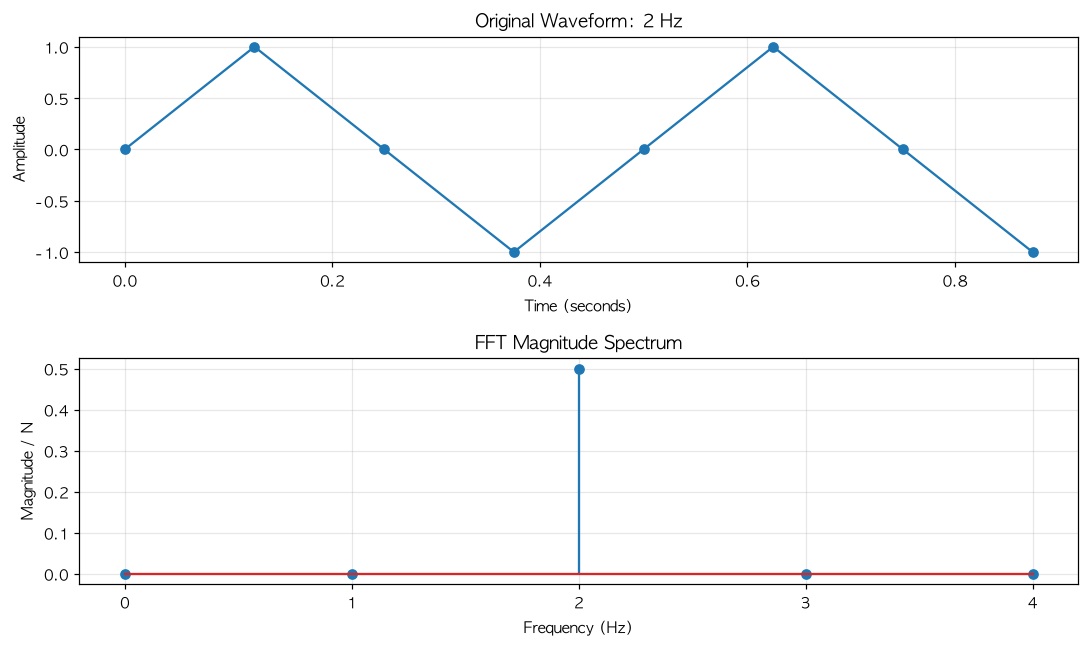

In [13]:
# ------------------------------------------------------------
# 6. 파형과 FFT 결과 비교
# ------------------------------------------------------------

demo_time = np.arange(len(demo_audio)) / demo_sr

fig, axes = plt.subplots(2, 1, figsize=(10, 6))

# 위쪽: 시간 영역
# 시간에 따라 진폭이 어떻게 변하는지 확인합니다.
axes[0].plot(demo_time, demo_audio, marker="o")
axes[0].set_title("Original Waveform: 2 Hz")
axes[0].set_xlabel("Time (seconds)")
axes[0].set_ylabel("Amplitude")
axes[0].grid(alpha=0.3)

# 아래쪽: 주파수 영역
# 어느 주파수 성분이 강하게 포함되어 있는지 확인합니다.
axes[1].stem(frequency_axis, fft_size)
axes[1].set_title("FFT Magnitude Spectrum")
axes[1].set_xlabel("Frequency (Hz)")
axes[1].set_ylabel("Magnitude / N")
axes[1].set_xticks(frequency_axis)
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [15]:
# ============================================================
# 7. 추가 확인: 왜 len(audio)로 나누는가?
# ============================================================

# 동일한 2Hz 사인파를 1초와 2초 동안 분석합니다.
# 두 신호의 주파수와 진폭은 같고, 샘플 수만 다릅니다.
# FFT 주파수 간격 = 샘플링 레이트(SR) / 샘플 수(N)
# 1초 음성: 8Hz / 8개 = 1Hz 간격 → 0, 1, 2, 3, 4Hz (5개)
# 2초 음성: 8Hz / 16개 = 0.5Hz 간격 → 0, 0.5, 1, ... 4Hz (9개)
# 같은 2Hz 성분도 1초는 인덱스 2, 2초는 인덱스 4에 저장됩니다.
# FFT 크기는 각각 4와 8이지만, 샘플 수로 나누면 모두 0.5입니다.
# 분석 구간이 길수록 주파수 간격은 작아지지만 시간 변화는 구분하기 어려워집니다.

# 1초 음성: 8개 샘플
time_1s = np.arange(8) / demo_sr #데이터 개수 : 8
audio_1s = np.sin(2 * np.pi * 2 * time_1s) 

# 2초 음성: 16개 샘플
time_2s = np.arange(16) / demo_sr #데이터 개수 : 16
audio_2s = np.sin(2 * np.pi * 2 * time_2s)

print("-"*20)
print(f"1초 음성의 음성 data : {audio_1s}")
print(f"2초 음성의 음성 data : {audio_2s}")
print("-"*20)

# 지수 표기 방지, 소수점 둘째 자리까지 표시
np.set_printoptions(suppress=True, precision=2)
# 각 음성의 FFT 결과
result_1s = np.fft.rfft(audio_1s) #1초 음성의 FFT 복소수 결과 5개
result_2s = np.fft.rfft(audio_2s) #2초 음성의 FFT 복소수 결과 9개

print("-"*20)
print(f"1초 음성의 FFT 결과 : {result_1s}")
print(f"2초 음성의 FFT 결과 : {result_2s}")
print("-"*20)

--------------------
1초 음성의 음성 data : [ 0.0000000e+00  1.0000000e+00  1.2246468e-16 -1.0000000e+00
 -2.4492936e-16  1.0000000e+00  3.6739404e-16 -1.0000000e+00]
2초 음성의 음성 data : [ 0.00000000e+00  1.00000000e+00  1.22464680e-16 -1.00000000e+00
 -2.44929360e-16  1.00000000e+00  3.67394040e-16 -1.00000000e+00
 -4.89858720e-16  1.00000000e+00  6.12323400e-16 -1.00000000e+00
 -7.34788079e-16  1.00000000e+00  8.57252759e-16 -1.00000000e+00]
--------------------
--------------------
1초 음성의 FFT 결과 : [ 0.+0.j  0.+0.j -0.-4.j  0.-0.j  0.+0.j]
2초 음성의 FFT 결과 : [ 0.+0.j  0.+0.j  0.+0.j  0.+0.j -0.-8.j  0.-0.j  0.-0.j  0.-0.j  0.+0.j]
--------------------


In [16]:
# ============================================================
# 1초와 2초 음성의 FFT 크기 비교
# 목적: 샘플 수가 달라질 때 FFT 크기가 어떻게 달라지는지 확인
# ============================================================

# 1. 각 음성의 FFT 계산
# FFT 결과는 주파수별 크기와 위상 정보를 담은 복소수 배열
result_1s = np.fft.rfft(audio_1s)
result_2s = np.fft.rfft(audio_2s)

# 2. 복소수의 크기 계산
# np.abs()는 각 주파수 성분의 복소수 크기를 계산
size_1s = np.abs(result_1s)
size_2s = np.abs(result_2s)

# 3. FFT 결과에 해당하는 실제 주파수(Hz) 계산
# 1초와 2초 음성은 샘플 수가 다르므로 주파수 간격도 다름
hz_1s = np.fft.rfftfreq(len(audio_1s), d=1 / demo_sr)
hz_2s = np.fft.rfftfreq(len(audio_2s), d=1 / demo_sr)

# 4. 주파수별 FFT 크기 비교
# 복소수 대신 크기만 출력하여 1초와 2초 음성을 비교
print("주파수 | 1초 FFT 크기 | 2초 FFT 크기")
print("-" * 40)

for hz in range(5):
    # 각 음성에서 해당 주파수에 가장 가까운 FFT 칸 찾기
    idx_1s = np.argmin(np.abs(hz_1s - hz))
    idx_2s = np.argmin(np.abs(hz_2s - hz))

    print(f"{hz:4d}Hz | {size_1s[idx_1s]:11.2f} | {size_2s[idx_2s]:11.2f}")

# 5. 2Hz 성분의 정규화 전후 비교
# 같은 2Hz 사인파이지만 2초 음성은 샘플 수가 두 배이므로
# 정규화하지 않은 FFT 크기도 두 배로 나타남
idx_1s = np.argmin(np.abs(hz_1s - 2))
idx_2s = np.argmin(np.abs(hz_2s - 2))

print("\n2Hz 성분의 정규화 전후 비교")
print("-" * 53)
print("구분  | 샘플 수 | 정규화 전 크기 | 정규화 후 크기")
print("-" * 53)

print(f"1초   | {len(audio_1s):7d} | {size_1s[idx_1s]:14.2f} | "
      f"{size_1s[idx_1s] / len(audio_1s):14.2f}")

print(f"2초   | {len(audio_2s):7d} | {size_2s[idx_2s]:14.2f} | "
      f"{size_2s[idx_2s] / len(audio_2s):14.2f}")

# 결과 해석
# - 같은 진폭의 2Hz 사인파이지만 1초 FFT 크기는 4, 2초는 8
# - FFT는 샘플들의 기여를 합산하므로 샘플 수에 따라 크기가 달라짐
# - 각 샘플 수로 나누면 두 경우 모두 0.5
# - 이것이 fft_size = np.abs(fft_result) / len(audio)를 사용하는 이유
# 예상 결과:
#
# 1초 음성 - 샘플 수: 8  / FFT 크기: 4.0
# 2초 음성 - 샘플 수: 16 / FFT 크기: 8.0
#
# 샘플 수로 나눈 결과
# 1초 음성: 0.5
# 2초 음성: 0.5
#
# 같은 진폭의 사인파라도 샘플이 두 배 많아지면
# 이 예제에서는 FFT 계수의 크기도 두 배가 됩니다.
#
# 샘플 수로 나누면 분석 길이에 따른 크기 차이를 보정할 수 있습니다.
#
# ============================================================
# 최종 정리
#
# 1. rfft(audio)
#    전체 음성을 주파수별로 분석하여 복소수 배열을 반환합니다.
#
# 2. np.abs(fft_result) / len(audio)
#    주파수별 복소수 크기를 계산하고 샘플 수로 정규화합니다.
#    이 값은 기여율(%)이나 원본 진폭 자체를 의미하지 않습니다.
#
# 3. rfftfreq(len(audio), d=1/sr)
#    각 FFT 결과가 실제 몇 Hz인지 계산합니다.
#
# FFT는 전체 구간의 주파수 성분을 분석합니다.
# 각 주파수가 언제 나타났는지는 STFT를 통해 분석합니다.
# ============================================================

주파수 | 1초 FFT 크기 | 2초 FFT 크기
----------------------------------------
   0Hz |        0.00 |        0.00
   1Hz |        0.00 |        0.00
   2Hz |        4.00 |        8.00
   3Hz |        0.00 |        0.00
   4Hz |        0.00 |        0.00

2Hz 성분의 정규화 전후 비교
-----------------------------------------------------
구분  | 샘플 수 | 정규화 전 크기 | 정규화 후 크기
-----------------------------------------------------
1초   |       8 |           4.00 |           0.50
2초   |      16 |           8.00 |           0.50


# 2026.10.23(금) 20h~

## SFFT

In [18]:
# 0부터 11까지의 숫자를 생성합니다.
# 실제 STFT에서는 이 숫자들이 음성의 샘플이라고 생각하면 됩니다.
numbers = np.arange(12)

# 한 번에 가져올 데이터의 개수
# STFT에서는 하나의 Frame 크기에 해당합니다.
frame_length = 6

# 다음 Frame으로 이동할 간격
# 6개를 가져온 후 3칸만 이동하므로 앞 Frame과 데이터가 겹칩니다.
hop_length = 3

# start는 각 Frame의 시작 위치입니다.
# 0 → 3 → 6 순서로 이동합니다.
for start in range(0, len(numbers) - frame_length + 1, hop_length):

    # 시작 위치부터 6개의 데이터를 잘라서 출력합니다.
    print("시작", start, "→ 조각", numbers[start:start + frame_length])

시작 0 → 조각 [0 1 2 3 4 5]
시작 3 → 조각 [3 4 5 6 7 8]
시작 6 → 조각 [ 6  7  8  9 10 11]


### Q. `range(0, len(numbers) - frame_length + 1, hop_length)`의 3개 인자는 각각 무엇인가?

아래 예시와 숫자는 모두 직접 실행해서 확인했습니다.

#### 1. `range(start, stop, step)` — 인자 3개
`range`는 **숫자를 일정한 간격으로 차례로 꺼내 주는 도구**입니다.

| 인자 | 뜻 | 이 셀의 값 |
|---|---|---|
| `start` | 시작값 (**포함**) | `0` |
| `stop` | 끝값 (★ **포함하지 않음**) | `len(numbers) - frame_length + 1` = `12 - 6 + 1` = `7` |
| `step` | 몇 칸씩 건너뛸지 (생략하면 `1`) | `hop_length` = `3` |

- 이 셀의 `range(0, 7, 3)`이 만드는 값: **`0, 3, 6`** (`0 → 3 → 6 → 다음은 9인데 7 미만이 아니므로 멈춤`)

#### 2. Java의 for문과 비교
질문하신 모양이 거의 맞습니다. 3씩 늘릴 때는 `++3`이 아니라 **`i += 3`** 입니다.
```java
// Java
for (int start = 0; start < 7; start += 3) { ... }
```
```python
# Python
for start in range(0, 7, 3):
    ...
```
| 부분 | Java | Python |
|---|---|---|
| 시작값 | `int start = 0` | `range(`**`0`**`, 7, 3)` |
| 계속 조건 | `start < 7` | `range(0, `**`7`**`, 3)` (7 **미만**까지, 7은 나오지 않음) |
| 증가 | `start += 3` | `range(0, 7, `**`3`**`)` |

#### 3. 인자를 줄여 쓰는 경우
| 코드 | 값 | 설명 |
|---|---|---|
| `range(5)` | `0, 1, 2, 3, 4` | 인자 1개 = `stop`만. `start=0`, `step=1` |
| `range(2, 5)` | `2, 3, 4` | 인자 2개 = `start`, `stop` |
| `range(0, 10, 3)` | `0, 3, 6, 9` | 인자 3개 |
| `range(10, 0, -3)` | `10, 7, 4, 1` | `step`이 **음수**면 거꾸로 감소 (`stop` 0은 포함하지 않음) |

#### 4. 주의할 점 (★)
- 인자는 **정수만** 가능합니다. `range(0, 1.5)`는 `TypeError`.
- `step`은 **0이 될 수 없습니다.** `range(0, 10, 0)`은 `ValueError`.
- `range(...)`는 숫자가 담긴 리스트가 아니라, **필요할 때 하나씩 꺼내 주는 객체**입니다. 한꺼번에 보고 싶으면 `list(range(0, 7, 3))` → `[0, 3, 6]`처럼 감쌉니다.

#### 5. 이 셀의 핵심: `stop`이 왜 `len(numbers) - frame_length + 1`인가
- `start`는 **조각(프레임)의 시작 위치**이고, 조각은 `start`부터 `frame_length`(6)개입니다.
- 조각이 `numbers` 밖으로 나가면 안 되므로, 가능한 **가장 큰 `start`** 는 `12 - 6 = 6`입니다(`numbers[6:12]` = `6 7 8 9 10 11`, 마지막 조각).
- 그런데 `stop`은 **포함되지 않는** 값입니다. `start = 6`까지 나오게 하려면 `stop`을 그보다 **1 크게** 해야 합니다 → `12 - 6 + 1 = 7`.
- **`+1`을 빼면** `range(0, 6, 3)` → `0, 3`만 나와서 **마지막 조각을 놓칩니다**(직접 확인).

| 상황 | 결과 (직접 확인) |
|---|---|
| 이 셀 (전체 12개, 조각 6개, 이동 3칸) | 조각 개수 = `(12 - 6) // 3 + 1` = **3개** (시작 0, 3, 6) |
| 전체가 조각보다 작을 때 (예: 4개) | `range(0, -1, 3)`이 비어서 **조각이 하나도 안 나옴** |
| 딱 나눠떨어지지 않을 때 (예: 13개) | 시작 0, 3, 6만 나오고 **마지막 남는 샘플(12번)은 어느 조각에도 안 들어감** |


In [19]:
from scipy.signal import stft

def compute_stft(sound, sr, frame_length=512, hop_length=128):
    """
    음성 신호를 짧은 구간으로 나누어 STFT를 수행합니다.
    반환하는 spectrum의 축은 (주파수, 시간)입니다.
    """

    # 창 길이와 이동 간격이 올바른지 확인
    if not (1 <= hop_length <= frame_length <= len(sound)):
        raise ValueError("1 ≤ 이동 간격 ≤ 창 길이 ≤ 샘플 수가 되도록 설정하세요.")

    frequencies, times, spectrum = stft(
        sound,
        fs=sr,                            # 샘플링 레이트(Hz)
        window="hann",                    # 구간 양 끝을 부드럽게 줄이는 창 함수
        nperseg=frame_length,             # FFT로 분석할 한 구간의 샘플 개수
        noverlap=frame_length-hop_length,  # 이웃 구간과 겹치는 샘플 개수
        nfft=frame_length,                # FFT 계산에 사용할 샘플 개수
        boundary=None,                    # 신호 앞뒤에 샘플을 추가하지 않음
        padded=False,                     # 마지막 구간을 채우기 위한 패딩 없음
        detrend=False,                    # 구간별 평균이나 추세를 제거하지 않음
        scaling="spectrum"                # 스펙트럼 크기 기준으로 계산
    )

    return frequencies, times, spectrum

### Q. `noverlap=frame_length-hop_length  # 이웃 구간과 겹치는 샘플 개수`가 왜 이런 식인가? (겹치는 개수 = hop_length 아닌가?)

**먼저 답:** 질문하신 직관("겹치는 개수 = hop_length")은 바로 앞 `range` 예제(`frame_length = 6`, `hop_length = 3`)에서는 **우연히 맞습니다.** `6 - 3 = 3`이라 겹치는 개수와 hop이 둘 다 3이기 때문입니다. 하지만 일반적으로는 **겹치는 개수 = frame_length − hop_length** 입니다. 아래 표·그림·숫자는 모두 직접 실행해서 확인했습니다.

#### 1. 두 개념은 "다른 것"을 잽니다
| 이름 | 무엇을 재나 | 비유 |
|---|---|---|
| `frame_length` (조각 길이) | 한 조각에 샘플이 몇 개 들어가나 | 돋보기(창문)의 **가로 길이** |
| `hop_length` (이동 간격) | 다음 조각이 **시작점에서 몇 칸 앞으로** 가나 | 돋보기를 **한 번에 밀어 주는 거리** |
| `noverlap` (겹치는 개수) | 앞 조각과 다음 조각이 **같이 쓰는** 샘플이 몇 개인가 | 돋보기를 밀었을 때 **앞뒤로 겹쳐 보이는 부분** |

- 돋보기 길이가 6칸이고 3칸만 밀면, **밀지 않고 남은 부분(6 − 3 = 3칸)** 이 앞 조각과 겹칩니다. 많이 밀수록 겹침은 줄고, 조금 밀수록 겹침이 커집니다.
- 그래서 **hop이 클수록 겹침은 작아지는 반대 관계**입니다. "겹침 = hop"이라면 hop을 키우면 겹침도 커져야 하는데, 실제로는 줄어듭니다.

#### 2. 숫자로 확인 (`frame_length = 6`, 샘플 12개)
| hop_length | 겹치는 개수 `6 − hop` | 시작 위치들 | 조각 수 |
|---|---|---|---|
| 1 | **5** | 0, 1, 2, 3, 4, 5, 6 | 7 |
| 2 | **4** | 0, 2, 4, 6 | 4 |
| **3** | **3** (hop과 우연히 같음) | 0, 3, 6 | 3 |
| 4 | **2** | 0, 4 | 2 |
| 6 | **0** (겹침 없음) | 0, 6 | 2 |
- hop = 3일 때만 두 값이 같고, 나머지에서는 다릅니다. 그래서 이 예제 하나만 보면 "겹침 = hop"으로 착각하기 쉽습니다.
- 바로 아래 그림에서 hop = 3, 2, 6을 직접 비교해 보세요. 빗금이 **겹치는 샘플**입니다.

#### 3. 왜 이 코드는 `hop_length`가 아니라 `noverlap`을 넣나
- `scipy.signal.stft`의 인자 목록에는 **`hop`에 해당하는 인자가 없고** `nperseg`(조각 길이)와 `noverlap`(겹치는 개수)을 받습니다(`inspect.signature`로 확인).
- 우리는 "얼마씩 이동할지(hop)"로 생각하는 게 편하니, 함수 안에서 **hop을 noverlap으로 바꿔 줍니다**: `noverlap = frame_length - hop_length`. 반대로 scipy 입장에서 이동 간격은 `nperseg - noverlap`(= hop)입니다.
- `compute_stft`의 기본값 `frame_length = 512`, `hop_length = 128`이면 `noverlap = 384`입니다. 조각의 `384 ÷ 512 = 75%`가 이웃 조각과 겹칩니다.


hop_length | noverlap(겹침) = frame_length - hop_length | 시작 위치들
         1 |                         5 개 | [0, 1, 2, 3, 4, 5, 6]
         2 |                         4 개 | [0, 2, 4, 6]
         3 |                         3 개 | [0, 3, 6]
         4 |                         2 개 | [0, 4]
         6 |                         0 개 | [0, 6]

STFT 확인 (frame 512, hop 128 → noverlap 384 )
spectrum 모양 (주파수 칸, 조각 개수): (257, 122)
이웃 조각의 시작 시각 차이 × SR = [128. 128. 128.] 샘플 (= hop_length)
조각 개수 공식 (샘플 수 - frame_length) // hop_length + 1 = 122


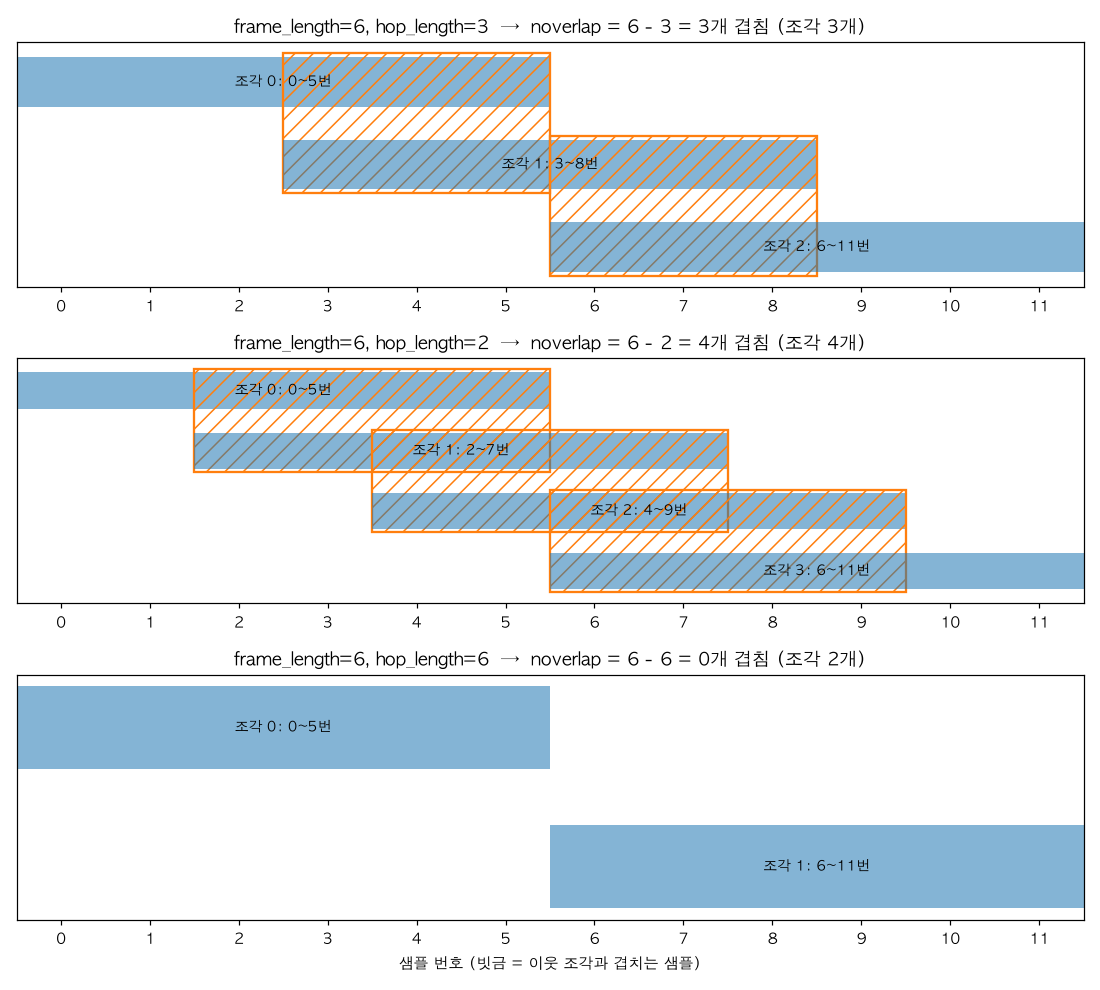

In [ ]:
# "겹치는 개수(noverlap) = 조각 길이 - 이동 간격"을 눈으로 확인하는 예제
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from scipy.signal import stft

numbers = np.arange(12)      # 샘플 12개 (0~11번)
frame_length = 6             # 조각 길이: 6개

fig, axes = plt.subplots(3, 1, figsize=(10, 9))
for ax, hop_length in zip(axes, [3, 2, 6]):
    starts = list(range(0, len(numbers) - frame_length + 1, hop_length))
    overlap = frame_length - hop_length          # 이웃 조각과 겹치는 샘플 개수

    for k, start in enumerate(starts):
        # 조각 하나 = start부터 frame_length개 (가로 막대)
        ax.barh(k, frame_length, left=start, height=0.6, alpha=0.55, color="tab:blue")
        ax.text(start + frame_length / 2, k, f"조각 {k}: {start}~{start + frame_length - 1}번",
                ha="center", va="center", fontsize=9)
        # 다음 조각과 겹치는 부분을 빗금 사각형으로 표시
        if k + 1 < len(starts) and overlap > 0:
            ax.add_patch(Rectangle((starts[k + 1], k - 0.35), overlap, 1.7,
                                   fill=False, hatch="//", edgecolor="tab:orange", linewidth=1.5))

    ax.set_xlim(0, len(numbers))
    ax.set_xticks(np.arange(len(numbers)) + 0.5)
    ax.set_xticklabels(numbers)
    ax.set_yticks([])
    ax.invert_yaxis()
    ax.set_title(f"frame_length={frame_length}, hop_length={hop_length}  →  noverlap = {frame_length} - {hop_length} = {overlap}개 겹침"
                 f" (조각 {len(starts)}개)")
axes[-1].set_xlabel("샘플 번호 (빗금 = 이웃 조각과 겹치는 샘플)")
plt.tight_layout()
plt.show()

# 표: hop_length를 바꾸면 겹침 개수와 조각 개수
print("hop_length | noverlap(겹침) = frame_length - hop_length | 시작 위치들")
for hop_length in [1, 2, 3, 4, 6]:
    starts = list(range(0, len(numbers) - frame_length + 1, hop_length))
    print(f"{hop_length:10d} | {frame_length - hop_length:25d} 개 | {starts}")

# 실제 scipy.signal.stft로 확인: noverlap을 frame_length - hop_length로 주면 조각이 hop_length씩 이동하는가?
sr = 16000
frame_length, hop_length = 512, 128
dummy = np.zeros(sr)         # 1초짜리 아무 소리 (모양만 확인하는 용도)
freqs, times, spectrum = stft(dummy, fs=sr, nperseg=frame_length,
                              noverlap=frame_length - hop_length, nfft=frame_length,
                              boundary=None, padded=False)
print("\nSTFT 확인 (frame 512, hop 128 → noverlap", frame_length - hop_length, ")")
print("spectrum 모양 (주파수 칸, 조각 개수):", spectrum.shape)
print("이웃 조각의 시작 시각 차이 × SR =", np.round(np.diff(times)[:3] * sr, 3), "샘플 (= hop_length)")
print("조각 개수 공식 (샘플 수 - frame_length) // hop_length + 1 =", (len(dummy) - frame_length) // hop_length + 1)


#### 4. 위 코드 셀의 실행 결과 읽기 (scipy로 직접 검증)
- `frame 512, hop 128` → `noverlap = 384`로 `stft`를 실행했을 때 `spectrum` 모양은 **`(257, 122)`** 입니다.
  - **257 = 512 ÷ 2 + 1**: 앞에서 배운 `rfft` 칸 수 공식과 같습니다(조각 하나를 FFT한 결과가 257칸).
  - **122개의 조각**: `(16000 − 512) // 128 + 1 = 122`. 앞의 `range` 설명에서 본 조각 개수 공식과 같습니다.
- **이웃 조각의 시작 시각 차이 × SR = 128 샘플** → `noverlap = frame − hop`으로 넣으면 조각이 정확히 `hop_length`(128)씩 이동합니다. 즉 `noverlap`을 이렇게 잡는 것이 "hop씩 이동"을 만든다는 것이 확인됩니다.

#### 5. 코드에서 같이 보이는 검사: `1 ≤ hop_length ≤ frame_length ≤ len(sound)`
- `hop_length ≥ 1`: hop이 0이면 `noverlap = frame_length`가 되어 scipy가 오류를 냅니다(`noverlap must be less than nperseg`, 직접 확인).
- `hop_length ≤ frame_length`: hop이 frame보다 크면 `noverlap`이 음수가 되고 조각 사이에 **분석되지 않는 샘플이 생깁니다.** 이 scipy 버전은 `noverlap = -1`도 오류 없이 받아 주는 것을 확인했습니다(조각 사이 건너뜀). 그래서 코드가 미리 막고 있습니다.
- `frame_length ≤ len(sound)`: 소리가 조각 하나보다 짧으면 조각이 하나도 안 나옵니다.

#### 6. 왜 일부러 겹치게 하나 (일반 지식, 이 노트북에서 확인하지 않음)
- 조각마다 `window="hann"`(양 끝을 부드럽게 줄이는 창)을 곱하면 조각 **가장자리 샘플의 영향이 작아집니다.** 조각을 겹치게 하면 어떤 조각에서 가장자리였던 샘플이 다른 조각에서는 가운데로 오게 되어 **놓치는 정보가 줄고**, 시간 방향으로 **더 촘촘하게** 볼 수 있습니다.
- 겹침이 클수록(= hop이 작을수록) 조각이 많아져서 **계산량과 결과 크기가 커집니다.**

#### 7. 한 장 요약
```text
frame_length  = 한 조각의 길이                  (돋보기 가로 길이)
hop_length    = 다음 조각 시작점까지의 거리      (한 번에 밀어 주는 거리)
noverlap      = frame_length - hop_length        (밀고도 겹쳐 남는 샘플 수)

hop ↑  →  noverlap ↓ , 조각 수 ↓            hop = frame  →  겹침 0
hop ↓  →  noverlap ↑ , 조각 수 ↑            hop = 1      →  겹침 frame-1
```


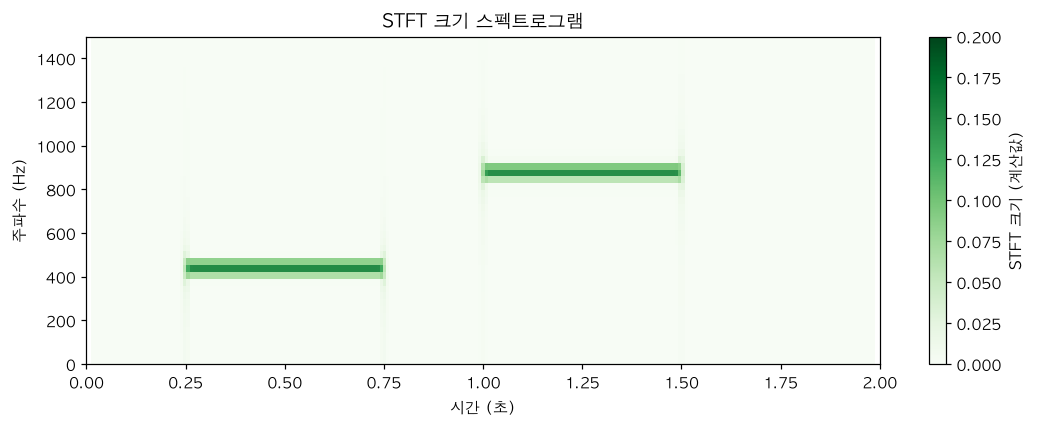

숫자 표의 모양: (257, 247)


In [25]:
# 1. STFT 분석 수행
# frequencies: 주파수 위치(Hz)
# frame_times: 각 분석 구간의 중심 시간(초)
# spectrum: 시간별·주파수별 FFT 결과(복소수)
frequencies, frame_times, spectrum = compute_stft(audio, sr)

# 2. 복소수 결과에서 크기(Magnitude)만 추출
# 크기가 클수록 해당 시간에 해당 주파수 성분이 강함
magnitude = np.abs(spectrum)

# 3. 스펙트로그램을 표시할 그래프 생성
fig, ax = plt.subplots(figsize=(10, 4))

# 4. 시간(X축), 주파수(Y축), 크기(색상)를 이용하여 시각화
mesh = ax.pcolormesh(
    frame_times, frequencies, magnitude,
    shading="auto",    # 색상 격자의 경계를 자동 처리
    cmap="Greens",      # 연한 초록(작은 값) → 진한 초록(큰 값)으로 크기 표현
    vmin=0,            # 색상으로 표시할 최솟값
    vmax=0.2           # 색상으로 표시할 최댓값
)

# 5. 그래프 제목과 축 설정
ax.set(
    xlabel="시간 (초)",
    ylabel="주파수 (Hz)",
    title="STFT 크기 스펙트로그램"
)

ax.set_xlim(0, len(audio) / sr)  # 전체 음성 시간 표시
ax.set_ylim(0, 1500)             # 0~1500Hz 주파수 범위만 표시

# 6. 색상이 나타내는 크기를 확인할 수 있도록 색상 막대 추가
fig.colorbar(mesh, ax=ax, label="STFT 크기 (계산값)")

plt.tight_layout()
plt.show()

# 7. STFT 결과의 배열 크기 확인
print("숫자 표의 모양:", magnitude.shape)

### Q. 색 막대의 "STFT 크기" 숫자는 의미가 있나? 언제, 어떻게 나온 숫자인가?

**한 줄 답:** 네, 의미가 있습니다. 색 막대는 **색을 숫자로 바꿔 읽는 눈금**이고, 그림의 **칸 하나하나의 색**은 위 코드의 `magnitude = np.abs(spectrum)` 값을 칠한 것입니다. 단, 막대에 보이는 **`0.000 ~ 0.200`이라는 범위는 계산된 값이 아니라 코드에서 정한 값**(`vmin=0`, `vmax=0.2`)입니다. 아래 수치는 직접 실행해서 확인했습니다.

#### 1. 어디서 나온 숫자인가 (순서대로)
```text
① compute_stft(audio, sr)    →  spectrum  : 시간별·주파수별 복소수 표 (257 × 247칸)
② magnitude = np.abs(spectrum) →  크기      : 복소수 → 크기(양의 실수)
③ ax.pcolormesh(..., magnitude, cmap="Greens", vmin=0, vmax=0.2)
                              →  칸마다 크기 값을 색으로 칠함 (0 = 가장 연한 색, 0.2 이상 = 가장 진한 색)
④ fig.colorbar(mesh, ...)     →  ③의 "색 ↔ 숫자" 대응표를 막대로 그림
```
- 즉 막대의 숫자는 **"이 색이면 크기가 이 정도"를 알려 주는 눈금**입니다.

#### 2. 칸 하나의 값은 어떻게 계산되나 (`scaling="spectrum"`)
시간 `0.496초`(그림에서 0.5초 부근) 칸을 손으로 다시 계산해 봤습니다(`frame_length = 512`).
1. 그 시간의 샘플 **512개**를 꺼냅니다(7680번 샘플부터, 그 조각의 **중심 시각**이 0.496초).
2. **Hann 창**을 곱합니다(양 끝을 부드럽게 줄임).
3. `np.fft.rfft`로 FFT를 합니다 → 복소수 257개(0 ~ 8000 Hz).
4. **Hann 창의 합(= 256)으로 나눕니다.** 이것이 `scaling="spectrum"`입니다.
5. `np.abs`로 크기를 구합니다.
- 이 손 계산과 `stft` 결과가 **완전히 같았습니다**(`np.allclose` → `True`). 가장 큰 칸은 `437.5 Hz`에서 `0.1494`였습니다. (바로 아래 "특정 시간의 가장 강한 주파수" 셀의 출력 `0.5초: 437.5 Hz / 크기: 0.1494`와 같은 값입니다.)

#### 3. 숫자는 무슨 뜻인가
- **순수한 사인파 하나의 크기 = 진폭의 절반.** 진폭 `0.1 / 0.3 / 0.6`인 사인파로 시험하니 크기가 `0.05 / 0.15 / 0.30`이었습니다. 이 노트북의 합성음은 진폭 `0.3`이라 **약 0.15**여야 하고, 실제 최대가 `0.1494`입니다(`440 Hz`가 칸 위치 `437.5 Hz`와 약간 달라서 조금 작아진 것으로 보임, 추정).
- 앞에서 배운 `rfft ÷ 샘플 수`의 "진폭의 절반"과 **같은 성질**입니다. 다만 `STFT`에서는 샘플 수 대신 **창의 합으로 나눕니다.**
- **단위가 없는 상대값**입니다. `÷ 32768`로 만든 `-1 ~ 1` 눈금의 소리에서 나온 값이라서, 퍼센트도 dB(데시벨)도 아닙니다. 값이 클수록 **그 시간에 그 주파수가 강하다**는 뜻입니다.
- **창 길이가 바뀌어도 거의 같습니다**: 256 / 512 / 1024샘플에서 최대가 `0.1498 / 0.1494 / 0.1475`. 창의 합으로 나누는 덕분에 샘플 수에 따라 크기가 달라지지 않습니다.

#### 4. `vmin=0`, `vmax=0.2`는 왜 이 값인가 (그리고 주의할 점)
- `vmax=0.2`는 **계산 결과가 아니라 사람이 정한 표시 범위**입니다. 실제 최대 `0.149`보다 약간 크게 잡아서, 색이 잘려 같은 색으로 뭉개지는 칸이 `0개`입니다(직접 확인).
- 대부분의 칸은 거의 **0**입니다(512샘플 창에서 `98.2%`의 칸이 `0.001` 미만). 그래서 그림의 대부분이 가장 연한 색입니다.
- **소리가 작은 데이터에서는 이 범위가 안 맞습니다.** 예를 들어 내 녹음은 파형 최대가 `0.0129`라서 STFT 크기도 이보다 훨씬 작을 것입니다(여러 주파수에 나뉘므로 한 칸 값은 더 작음, 추정). `vmax=0.2`로 그리면 거의 안 보이니 `vmax`를 낮춰야 합니다.
- 소리 크기의 차이가 큰 데이터는 **로그 눈금(dB)** 으로 그리는 경우도 많습니다(일반 지식, 이 노트북에서는 쓰지 않음).


# 2026.10.23(금) 21h~

In [26]:
# STFT 분석 결과에서 특정 시간(0.5초, 1.2초)에 가장 강하게 나타나는 주파수를 찾아 출력하는 실습
# 0.5초와 1.2초에서 가장 강한 주파수를 확인
for target_time in [0.5, 1.2]:

    # STFT 시간 배열에서 목표 시간과 가장 가까운 위치 찾기
    # STFT는 모든 순간을 분석하는 것이 아니라 일정한 간격으로 이동하면서 분석(정확히 0.5초에 해당하는 분석 구간이 없을 수도 있음)
    # frame_times - target_time: 목표 시간과 각 분석 시간의 차이
    # np.abs(...): 차이를 양수로 변환
    # np.argmin(...): 차이가 가장 작은 위치 찾기 
    # 즉, 0.5초와 가장 가까운 STFT 분석 구간을 선택
    column = int(np.argmin(np.abs(frame_times - target_time)))

    # 해당 시간의 모든 주파수 성분 크기 추출
    # 복소수 결과에서 크기(Magnitude)
    band = magnitude[:, column]

    # 가장 큰 크기를 가진 주파수 칸을 찾아 Hz로 출력
    print(f"{target_time}초: {frequencies[int(np.argmax(band))]:.1f} Hz / 크기: {band.max():.4f}")

0.5초: 437.5 Hz / 크기: 0.1494
1.2초: 875.0 Hz / 크기: 0.1475


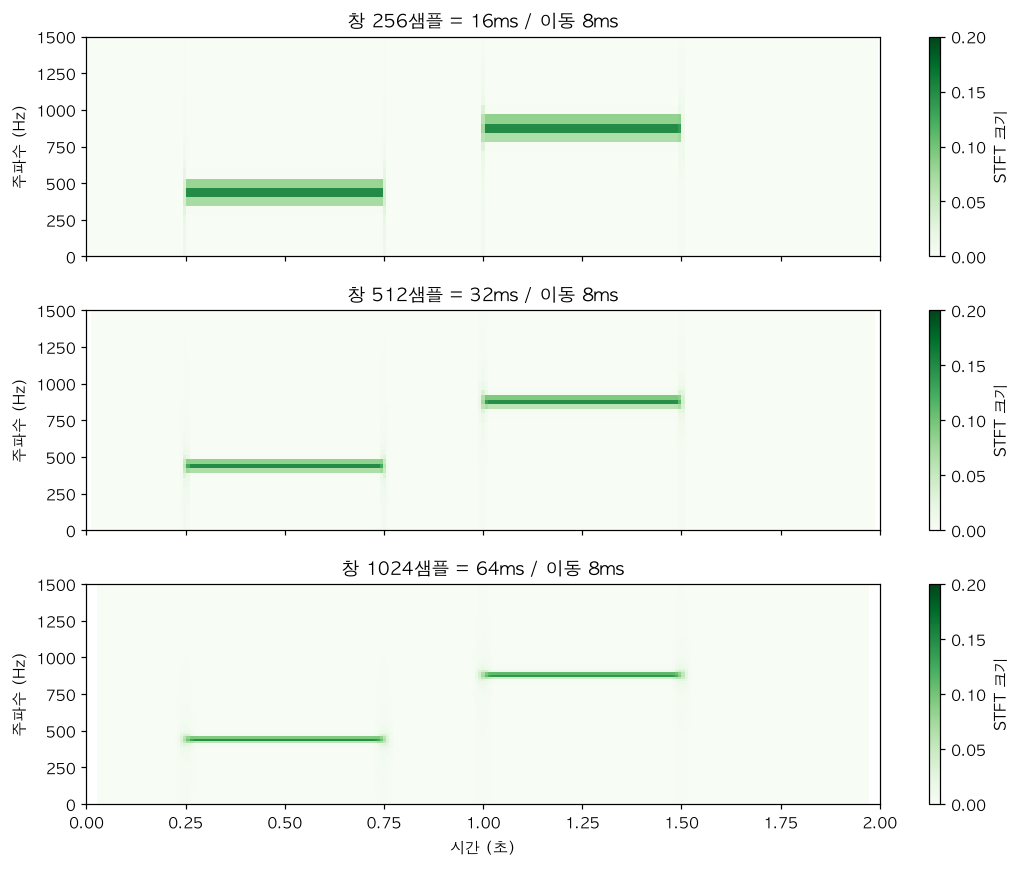

In [ ]:
fig, axes = plt.subplots(3, 1, figsize=(10, 8), sharex=True, sharey=True)
for ax, frame_length in zip(axes, [256, 512, 1024]):
    f, t, z = compute_stft(audio, sr, frame_length=frame_length, hop_length=128)
    mesh = ax.pcolormesh(t, f, np.abs(z), shading="auto", cmap="Greens", vmin=0, vmax=0.2)
    ax.set_title(f"창 {frame_length}샘플 = {frame_length/sr*1000:.0f}ms / 이동 8ms")
    ax.set_ylabel("주파수 (Hz)")
    ax.set_ylim(0, 1500)
    ax.set_xlim(0, 2)
    fig.colorbar(mesh, ax=ax, label="STFT 크기")
axes[-1].set_xlabel("시간 (초)")
plt.tight_layout()
plt.show()

# 실행 결과 = 창 샘플 크기가 커질 수록 아래 그래프? 두께는 얇아짐 -> 나의 질문 = qu'est-ce que ça veut dire?

### Q. "창 샘플 크기가 커질수록 아래 그래프는 두께가 얇아짐" — 무슨 뜻인가? (qu'est-ce que ça veut dire? = 그게 무슨 뜻이야?)

**한 줄 답:** 위 그림의 **가로 띠 하나는 "한 음(440 Hz 또는 880 Hz)"** 이고, 띠의 **세로 두께 = 그 음의 주파수를 얼마나 넓게 퍼뜨려 보는가**입니다. 창(조각)이 길수록 두께가 얇다 = **"그 음이 정확히 몇 Hz인지 더 좁게 짚어낸다"** 는 뜻입니다(주파수 정밀도가 올라감). 대신 **가로 방향(시간) 경계는 흐려집니다.** 아래 숫자는 직접 실행해서 확인했습니다.

#### 1. 그림 읽는 법
- 세 그래프는 **같은 소리**(440 Hz → 880 Hz)를 **창 길이만 바꿔서**(256 / 512 / 1024샘플 = 16 / 32 / 64 ms, 이동 간격은 모두 8 ms) 그린 것입니다.
- 가로축 = 시간, 세로축 = 주파수, 색 = 그 시간·주파수의 크기.
- 소리는 440 Hz(0.25~0.75초)와 880 Hz(1.0~1.5초) **딱 두 음**뿐입니다. 그런데 그림에서는 **선이 아니라 띠**로 보입니다. 이 **띠의 세로 폭**이 "두께"입니다.


In [ ]:
# 창 길이를 바꾸면 440 Hz 띠의 "세로 두께(주파수 폭)"와 "가로 경계(시간 번짐)"가 어떻게 변하는지 숫자로 확인
print("창 길이 | 창 시간 | 주파수 칸 간격 | 0.5초 봉우리의 폭(최대의 절반 이상인 칸) | 소리가 켜지는 데 걸리는 시간(10%→90%)")
for frame_length in [256, 512, 1024]:
    f, t, z = compute_stft(audio, sr, frame_length=frame_length, hop_length=128)
    m = np.abs(z)

    # 1) 세로 두께: 0.5초(440 Hz 음이 한창 나는 때)에서 크기가 최대의 절반 이상인 주파수 칸이 몇 개인가
    column = int(np.argmin(np.abs(t - 0.5)))
    profile = m[:, column]
    wide_bins = int((profile >= profile.max() / 2).sum())
    spacing = sr / frame_length                      # 주파수 칸 하나의 간격(Hz)
    width_hz = wide_bins * spacing

    # 2) 가로 번짐: 440 Hz 칸의 크기가 소리 시작(0.25초) 부근에서 10% → 90%로 올라가는 데 걸리는 시간
    row = int(profile.argmax())
    plateau = m[row][(t > 0.40) & (t < 0.60)].mean()  # 소리가 안정적으로 나는 구간의 평균 크기
    area = (t > 0.1) & (t < 0.45)
    ratio = m[row][area] / plateau
    t10 = t[area][np.argmax(ratio >= 0.1)]
    t90 = t[area][np.argmax(ratio >= 0.9)]

    print(f"{frame_length:6d} | {frame_length / sr * 1000:5.0f} ms | {spacing:9.3f} Hz | "
          f"{wide_bins}칸 x {spacing:.2f} = {width_hz:6.1f} Hz | {(t90 - t10) * 1000:5.1f} ms")

# 참고: 이동 간격(hop)이 128샘플 = 8 ms이므로 시간 값은 8 ms 단위로만 읽을 수 있습니다.


창 길이 | 창 시간 | 주파수 칸 간격 | 0.5초 봉우리의 폭(최대의 절반 이상인 칸) | 소리가 켜지는 데 걸리는 시간(10%→90%)
   256 |    16 ms |    62.500 Hz | 2칸 x 62.50 =  125.0 Hz |   8.0 ms
   512 |    32 ms |    31.250 Hz | 2칸 x 31.25 =   62.5 Hz |  16.0 ms
  1024 |    64 ms |    15.625 Hz | 2칸 x 15.62 =   31.2 Hz |  32.0 ms


#### 2. 숫자로 본 "두께" (바로 위 코드 셀의 출력)
| 창 길이 | 창 시간 | 주파수 칸 간격 `SR ÷ 창 길이` | 봉우리 폭(반 높이 이상) | 소리가 켜지는 데 걸리는 시간 |
|---|---|---|---|---|
| 256 | 16 ms | 62.5 Hz | **125 Hz** (넓음) | 8 ms |
| 512 | 32 ms | 31.25 Hz | **62.5 Hz** | 16 ms |
| 1024 | 64 ms | 15.6 Hz | **31 Hz** (얇음) | 32 ms |
- **세로 두께(주파수 방향):** 창이 2배 길어질 때마다 **절반**으로 얇아집니다(125 → 62.5 → 31 Hz). 이유: 칸 간격이 `SR ÷ 창 길이`라서 창이 길수록 칸이 촘촘해지기 때문입니다. 앞에서 배운 "구간 FFT의 칸 간격 = 1 ÷ 구간 길이(초)"와 같은 규칙입니다.
- **가로 번짐(시간 방향):** 같은 변화에서 소리가 켜지는 데 걸리는 시간이 **2배씩 늘어납니다**(8 → 16 → 32 ms). 소리의 시작과 끝이 **흐릿해진다**는 뜻입니다. (이동 간격이 8 ms라서 시간은 8 ms 단위로만 잴 수 있고, 256샘플의 `8 ms`는 그 측정 한계에 가깝습니다.) 그림에서는 아래 그래프일수록 띠의 **왼쪽·오른쪽 끝**(0.25, 0.75, 1.0, 1.5초)이 부드럽게 번집니다.

#### 3. 왜 이 비교를 했나 — "창 길이는 정답이 없는 선택"
- STFT에서 **창 길이는 가장 중요한 설정값 중 하나**입니다. 이 비교는 그 값을 바꿨을 때 그림이 어떻게 달라지는지 눈으로 보여 주려는 것입니다.
- 핵심 결론은 **서로 맞바꾸는 관계(trade-off)** 입니다.

| | 창이 짧을 때 (256) | 창이 길 때 (1024) |
|---|---|---|
| **주파수** (몇 Hz인가) | 띠가 두꺼움 → **덜 정밀** | 띠가 얇음 → **더 정밀** |
| **시간** (언제인가) | 경계가 또렷함 → **더 정밀** | 경계가 번짐 → **덜 정밀** |

- **둘 다 좋게 만들 수는 없습니다.** 시간과 주파수를 동시에 아주 정밀하게 알 수는 없다는 성질로 알려져 있습니다(일반 지식, 이 노트북에서 증명하지 않음). 앞 수업의 요점 "FFT는 언제를 모른다"가 STFT에서 이렇게 **조각 길이와 맞교환**하는 모양으로 나타납니다.

#### 4. 해석 — 무엇을 보고 창 길이를 고르나
- 이 합성음은 **한 번에 하나의 음만** 길게 나므로 창이 길수록(얇은 띠) 읽기 쉬워 보입니다. 하지만 **사람 말소리는 짧은 순간 안에서 소리가 빠르게 바뀝니다.** 그래서 창을 너무 길게 하면 빠른 변화가 뭉개질 수 있습니다(일반 지식).
- 반대로 창을 너무 짧게 하면 비슷한 주파수들이 서로 **구분되지 않고** 하나로 뭉칩니다. 예를 들어 256샘플 창에서는 한 음의 띠 폭이 약 125 Hz라서, 그보다 가까운 두 음은 **하나의 두꺼운 띠로 뭉쳐 보일 수 있습니다**(위 표의 폭에서 이끌어 낸 추론이며, 두 음을 실제로 섞어 실험하지는 않았습니다).
- 음성 인식 분야에서는 창을 수십 ms(20~30 ms 안팎), 이동을 10 ms 안팎으로 두는 경우가 흔하다고 알려져 있습니다(일반 지식, 이 노트북에서 확인하지 않음). 이 수업의 기본값 `512샘플 = 32 ms`, `128샘플 = 8 ms`도 비슷한 범위입니다.
- **한 줄 정리:** 창 길이는 "**무엇을 더 정밀하게 보고 싶은가**"(음의 높이 vs 소리가 바뀌는 순간)에 따라 고르는 값입니다.


## 21h25~ pop quiz

### 나의 답변
1. FFT는 음성을 구성하는 주파수를 분석하는 방법입니다. 음성 전체 구간에 어떤 주파수가 얼마나 들어있는지 분석하는데, 그 주파수가 언제 나타났는지는 알 수 없습니다.
2. STFT는 음성의 시간별 주파수를 분석하는 방법입니다. 마치 동영상을 작은 부분으로 잘라서 보면 각 부분에서 어떤 일이 일어나는지 볼 수 있는 것과 같습니다. 윈도우 크기가 크면 주파수를 더 세밀하게 알 수 있지만, 시간 구분은 흐려집니다(trade-off, 작으면 그 반대).

### 강사님 제시 답변
1. FFT는 음성 신호에 포함된 주파수 성분과 크기를 분석하지만, 각 주파수가 언제 나타났는지는 알기 어렵습니다.
2. STFT는 음성을 짧은 구간(Window)으로 나누어 FFT를 반복함으로써 시간에 따른 주파수 변화를 분석합니다.
   - 윈도우가 짧으면 시간 변화를 세밀하게 관찰할 수 있지만 주파수 구분 능력은 낮아집니다.
   - 반대로 윈도우가 길면 주파수를 세밀하게 구분할 수 있지만 빠른 시간 변화를 파악하기 어렵습니다.
   - 이처럼 시간 해상도와 주파수 해상도 사이에 발생하는 상충 관계를 Trade-off라고 합니다.

### 피드백

방향은 맞고, 핵심(FFT와 STFT의 차이, 창 크기의 trade-off)을 모두 짚었습니다. 아래 평가는 이 노트북에서 확인한 내용에 근거한 것입니다(문제가 정확히 어떻게 출제됐는지는 확인하지 못함).

**1번 (FFT) — 좋음**
- 틀린 곳이 없습니다. "음성 **전체 구간**에 어떤 주파수가 **얼마나** 있는지 알려 주지만 **언제**인지는 알 수 없다"까지 적어서 STFT와 차이가 드러납니다.
- 강사님 답과 비교하면 **"주파수 성분과 크기"** 라는 표현이 더 있습니다. 필요하면 "주파수별 크기(와 위상)를 분석"을 덧붙이면 됩니다.

**2번 (STFT) — 좋음, 한 가지 보강**
- "시간별 주파수를 분석한다"는 맞습니다.
- **동영상 비유는 좋습니다.** 한 가지 차이만 알아 두세요. STFT의 조각은 **겹쳐 가며** 자르는 경우가 많습니다(이 수업의 `frame_length`, `hop_length`).
- **trade-off 설명이 정확합니다.** 이 노트북에서 직접 측정한 값이 뒷받침합니다. 창을 256 → 512 → 1024샘플로 키우면 띠의 주파수 폭은 125 → 62.5 → 31 Hz로 절반씩 줄고, 소리가 켜지는 데 걸리는 시간은 8 → 16 → 32 ms로 2배씩 늘었습니다.
- **보강하면 좋은 점:** 강사님 답에 있는 **"짧은 구간(Window)으로 나누어 FFT를 반복한다"** 가 내 답에는 직접 적혀 있지 않습니다(비유에 담겨 있음). 한 문장을 더하면 "무엇을 하는지"가 분명해집니다. 또 용어로 **"시간 해상도"와 "주파수 해상도"** 를 쓰면 강사님 답과 같은 표현이 됩니다.

**강사님 답과의 비교**
| 항목 | 내 답변 | 강사님 답 | 판정 |
|---|---|---|---|
| FFT가 아는 것 | 전체 구간의 주파수와 크기 | 주파수 성분과 크기 | 일치 |
| FFT가 모르는 것 | 언제 나타났는지 | 각 주파수가 언제 나타났는지 | 일치 |
| STFT가 하는 일 | 시간별 주파수 분석(동영상 비유) | 짧은 구간으로 나누어 FFT 반복 | 일치, **"FFT를 반복"만 보강** |
| 창이 클 때 | 주파수 세밀, 시간 흐림 | 주파수 구분 좋음, 빠른 시간 변화 파악 어려움 | 일치 |
| 창이 작을 때 | "그 반대" | 시간 변화 세밀, 주파수 구분 낮음 | 일치(구체적으로 풀어 쓰면 더 좋음) |
| trade-off | 용어 사용 | **시간 해상도 ↔ 주파수 해상도**의 상충 관계로 정의 | 일치, 정의를 한 줄 덧붙이면 좋음 |

**한 문장씩 보강한 제출용 예시**
> 1. FFT는 음성 **전체 구간**에 어떤 주파수가 **얼마나** 들어 있는지 분석하지만, 그 주파수가 **언제** 나타났는지는 알 수 없습니다.
> 2. STFT는 음성을 **짧은 구간(창)으로 나누어 구간마다 FFT를 반복**해서 **시간별 주파수**를 분석합니다. 마치 동영상을 작은 장면으로 잘라 각 장면에서 무슨 일이 일어나는지 보는 것과 같습니다. 창이 크면 주파수 해상도는 높아지지만 시간 해상도는 낮아지고, 창이 작으면 그 반대입니다. 이 상충 관계를 trade-off라고 합니다.


In [29]:
for hop_length in [64, 128, 256]:
    f, t, z = compute_stft(audio, sr, frame_length=512, hop_length=hop_length)
    print("창: 32ms / 이동:", hop_length / sr * 1000, "ms",
          "/ 시간 칸 수:", z.shape[1],
          "/ 원래 음성 길이:", len(audio) / sr, "초")

창: 32ms / 이동: 4.0 ms / 시간 칸 수: 493 / 원래 음성 길이: 2.0 초
창: 32ms / 이동: 8.0 ms / 시간 칸 수: 247 / 원래 음성 길이: 2.0 초
창: 32ms / 이동: 16.0 ms / 시간 칸 수: 124 / 원래 음성 길이: 2.0 초


In [30]:
for frame, hop in [(512, 128), (512, 256), (1024, 128)]:
    f, t, z = compute_stft(audio, sr, frame, hop)
    print(f"창 {frame/sr*1000:.0f}ms / 이동 {hop/sr*1000:.0f}ms / 표 {z.shape} / 원본 {len(audio)/sr:.2f}초")

창 32ms / 이동 8ms / 표 (257, 247) / 원본 2.00초
창 32ms / 이동 16ms / 표 (257, 124) / 원본 2.00초
창 64ms / 이동 8ms / 표 (513, 243) / 원본 2.00초


### Q. 마지막 두 코드 셀(`hop_length`만 바꾼 셀 / `frame`과 `hop`을 같이 바꾼 셀)의 의미와 서로의 관계

수치는 이 코드를 그대로 실행해서 확인했습니다. 두 셀은 **서로 관계가 있습니다.** 둘 다 같은 것을 보고 있기 때문입니다.

#### 1. 두 셀이 공통으로 보는 것: STFT 결과 표의 "모양"
- `compute_stft(...)`가 돌려주는 `z`는 **주파수 × 시간의 표**입니다. `z.shape = (세로: 주파수 칸 수, 가로: 시간 칸 수)`.
- 두 셀은 `frame_length`(창 길이)와 `hop_length`(이동 간격)를 바꿨을 때 **이 표의 세로·가로가 각각 어떻게 변하는지**를 확인하는 실험입니다.

#### 2. 첫 번째 셀: `hop_length`만 바꿈 (창은 512 고정)
| hop | 이동 시간 | 시간 칸 수 | 계산 `(32000 - 512) // hop + 1` |
|---|---|---|---|
| 64 | 4 ms | **493** | 493 |
| 128 | 8 ms | **247** | 247 |
| 256 | 16 ms | **124** | 124 |
- hop을 **절반**으로 줄이면 시간 칸이 **약 2배**가 됩니다(124 → 247 → 493). 앞에서 본 조각 개수 공식 `(전체 길이 - frame) // hop + 1`과 정확히 맞습니다.
- **"원래 음성 길이: 2.0초"는 계속 같습니다.** hop은 표를 **얼마나 촘촘히 그리는지**를 바꿀 뿐, 소리의 길이를 바꾸지 않는다는 것을 같이 보여 줍니다.

#### 3. 두 번째 셀: `frame`과 `hop`을 함께 바꿈
| frame | hop | 표 모양 (세로, 가로) | 해석 |
|---|---|---|---|
| 512 | 128 | (**257**, **247**) | 기준. 세로 `257 = 512 ÷ 2 + 1` |
| 512 | **256** | (257, **124**) | **hop만 2배** → 세로 그대로, **가로가 절반** |
| **1024** | 128 | (**513**, 243) | **frame만 2배** → **세로가 약 2배**(`1024 ÷ 2 + 1 = 513`), 가로는 거의 그대로 |
- 세 번째 줄의 가로가 `247`이 아니라 **`243`**인 이유: 창이 길어지면 마지막 조각이 일찍 끝나서 조각이 4개 줄기 때문입니다(`(32000 - 1024) // 128 + 1 = 243`). hop은 같습니다.

#### 4. 두 셀의 관계 — "하나의 공식을 두 방향에서 확인"
```text
표 모양 = ( frame ÷ 2 + 1 ,  (전체 샘플 수 - frame) // hop + 1 )
              └ 세로(주파수 칸)        └ 가로(시간 칸)
```
| | 무엇이 정하나 | 칸 사이의 간격 |
|---|---|---|
| **세로 (주파수 칸 수)** | **`frame_length`** (hop과 무관) | `SR ÷ frame` (512 → 31.25 Hz, 1024 → 15.6 Hz) |
| **가로 (시간 칸 수)** | 주로 **`hop_length`** (frame은 조금) | `hop ÷ SR` (128 → 8 ms) |
- **첫 번째 셀**은 `hop`만 바꿔서 **가로 축**이 어떻게 변하는지 따로 봅니다.
- **두 번째 셀**은 `frame`을 바꾼 경우까지 넣어서, **세로 축은 frame이 결정하고 가로 축은 hop이 결정한다**는 역할 분담을 구분해서 보여 줍니다. (두 셀을 따로 보면 "창을 바꿀 때와 hop을 바꿀 때 무엇이 다른지" 한눈에 안 들어오는데, 모아 놓으면 이 대응이 보입니다.)
- 시간 칸의 시각은 **조각의 중심**입니다. 그래서 첫 칸이 `0초`가 아니라 `0.016초`(= `512 ÷ 2 ÷ 16000`)입니다(직접 확인).

#### 5. pop quiz의 trade-off와 어떻게 이어지나 (★ 중요한 구분)
- pop quiz의 "창이 크면 주파수가 세밀하고 시간이 흐려진다"는 **`frame_length`** 이야기입니다. **`hop_length`는 이 trade-off를 정하지 않습니다.**
- hop을 줄이면 시간 칸이 늘어나 **표가 촘촘해지지만, 소리가 켜지는 순간의 "번짐"은 줄어들지 않습니다.** 직접 측정(440 Hz 음이 켜지는 데 걸리는 시간, 10%→90%):

  | frame | hop | 소리가 켜지는 데 걸리는 시간 |
  |---|---|---|
  | 512 | 64 | 16 ms |
  | 512 | 128 | 16 ms |
  | 512 | 256 | 16 ms |
  | 1024 | 128 | **32 ms** |
  | 256 | 128 | 8 ms (이동 간격 한계 수준) |
- 즉 **번짐(시간 해상도)은 창 길이가 정하고, hop은 그 번짐을 얼마나 촘촘히 기록하느냐**입니다. 비유하면 동영상에서 **창 길이 = 셔터가 열려 있는 시간(흐릿함)**, **hop = 초당 프레임 수(촘촘함)** 입니다. 프레임 수를 늘려도 한 장 한 장의 흐릿함은 그대로입니다.
- 그래서 설정 순서는 **① `frame`으로 시간/주파수 해상도의 균형을 고르고, ② `hop`으로 표를 얼마나 촘촘히(= 얼마나 많은 계산·저장을 할지) 만들지 고르는 것**입니다.

#### 6. 대가: 표가 커지고 겹침이 커짐
| frame | hop | 겹침 `frame - hop` (비율) | 표의 복소수 개수 |
|---|---|---|---|
| 512 | 256 | 256 (50%) | 31,868 |
| 512 | 128 | 384 (75%) | 63,479 |
| 512 | 64 | 448 (87.5%) | 126,701 |
| 1024 | 128 | 896 (87.5%) | 124,659 |
- hop을 절반으로 줄이면 표가 **약 2배**로 커지고, `frame`을 2배로 키워도 세로가 2배가 되어 표가 **약 2배**로 커집니다. 촘촘할수록(hop↓) 그리고 주파수를 세밀하게 볼수록(frame↑) **계산량과 데이터가 늘어납니다.**
- 이 `(주파수 × 시간)` 표가 이후 스펙트로그램과 모델 입력의 **모양(shape)** 이 됩니다(01 노트북의 로드맵에서 "입력 모양이 어떻게 바뀌나"로 예고한 부분입니다).

#### 7. 한 장 요약
```text
frame ↑  →  세로(주파수 칸) ↑ , 주파수 정밀도 ↑ , 시간 번짐 ↑   ← pop quiz의 trade-off
hop   ↓  →  가로(시간 칸) ↑  , 표가 촘촘 , 번짐은 그대로 , 계산량 ↑
```


In [32]:
frequencies, frame_times, spectrum = compute_stft(audio, sr, 512, 128)
magnitude = np.abs(spectrum)
selected_column = int(np.argmin(np.abs(frame_times - 0.5))) # 0.5초에 가장 가까운 시간 칸
one_frame = magnitude[:, selected_column]                 # 모든 주파수 행, 선택한 열 하나

print("전체 모양 (주파수, 시간):", magnitude.shape)
print("선택한 프레임 중심:", round(float(frame_times[selected_column]), 3), "초")
print("선택한 열 하나의 모양:", one_frame.shape)
print("가장 큰 칸의 주파수:", frequencies[int(np.argmax(one_frame))], "Hz")

전체 모양 (주파수, 시간): (257, 247)
선택한 프레임 중심: 0.496 초
선택한 열 하나의 모양: (257,)
가장 큰 칸의 주파수: 437.5 Hz


### Q. 바로 위 코드 셀을 한눈에 이해하기 (변수 지도 + 그림으로 보기)

이 셀은 한 문장으로 말하면 **"STFT 표에서 0.5초 부근의 열(세로 한 줄)을 꺼내서, 그 열에서 가장 센 주파수를 찾는 것"** 입니다. 변수가 많아서 어려운 것이니, **① 변수가 각각 무엇인지**, **② 그것들이 어떻게 이어지는지**를 먼저 보고, 아래 그림 4장으로 확인하세요. 수치는 직접 실행해서 확인했습니다.

#### 1. 변수 지도 (이름 → 무엇 → 모양)
| 변수 | 무엇인가 | 모양 | 이 예제의 값 |
|---|---|---|---|
| `audio` | 원본 소리 (2초) | `(32000,)` | 샘플 32000개 |
| `sr` | 샘플링 레이트 | 숫자 | `16000` |
| `spectrum` | STFT 결과: 시간별·주파수별 **복소수 표** | `(257, 247)` | 표 칸 63,479개 |
| `magnitude` | `spectrum`의 **크기만** 꺼낸 표 (`np.abs`) | `(257, 247)` | 0 이상의 실수 |
| `frequencies` | **표의 세로 칸 이름표** (각 행이 몇 Hz인가) | `(257,)` | `0, 31.25, 62.5, …, 8000` |
| `frame_times` | **표의 가로 칸 이름표** (각 열이 몇 초인가) | `(247,)` | `0.016, 0.024, …, 1.984` |
| `selected_column` | 0.5초에 가장 가까운 **열 번호** | 숫자 | `60` |
| `one_frame` | 그 열 **하나** (주파수별 크기) | `(257,)` | 0.5초 부근의 크기 257개 |

- 세로(행) = **주파수**, 가로(열) = **시간**입니다. `(257, 247)`은 "행 257개 × 열 247개"를 뜻합니다.
- **`frequencies`와 `frame_times`는 `magnitude`의 "눈금(이름표)"** 입니다. `magnitude[3, 10]`이 "몇 Hz, 몇 초의 값인지"를 `frequencies[3]`, `frame_times[10]`이 알려 줍니다.

#### 2. 흐름도 (코드 순서 그대로)
```text
audio (소리 2초) ──compute_stft(audio, sr, 512, 128)──▶ spectrum (복소수 표, 257 × 247)
                                                           │ np.abs(...)
                                                           ▼
                                                    magnitude (크기 표, 257 × 247)
                                                           │
 frame_times ──"0.5초와 가장 가까운 열은?"──▶ selected_column = 60
                                                           │ magnitude[:, 60]    ( : = 모든 행, 60 = 이 열)
                                                           ▼
                                                    one_frame (열 하나, 257개)
                                                           │ np.argmax(one_frame) → 가장 큰 칸의 번호 14
                                                           ▼
                                           frequencies[14] = 437.5 Hz   ← 그 칸의 주파수
```


조각의 첫 샘플 번호: 7680 / 마지막 샘플 번호: 8191
조각의 시간 구간: 0.480 ~ 0.512초 / 중심 0.496초
frequencies[14] = 437.5 Hz  (칸 번호 × 31.25)


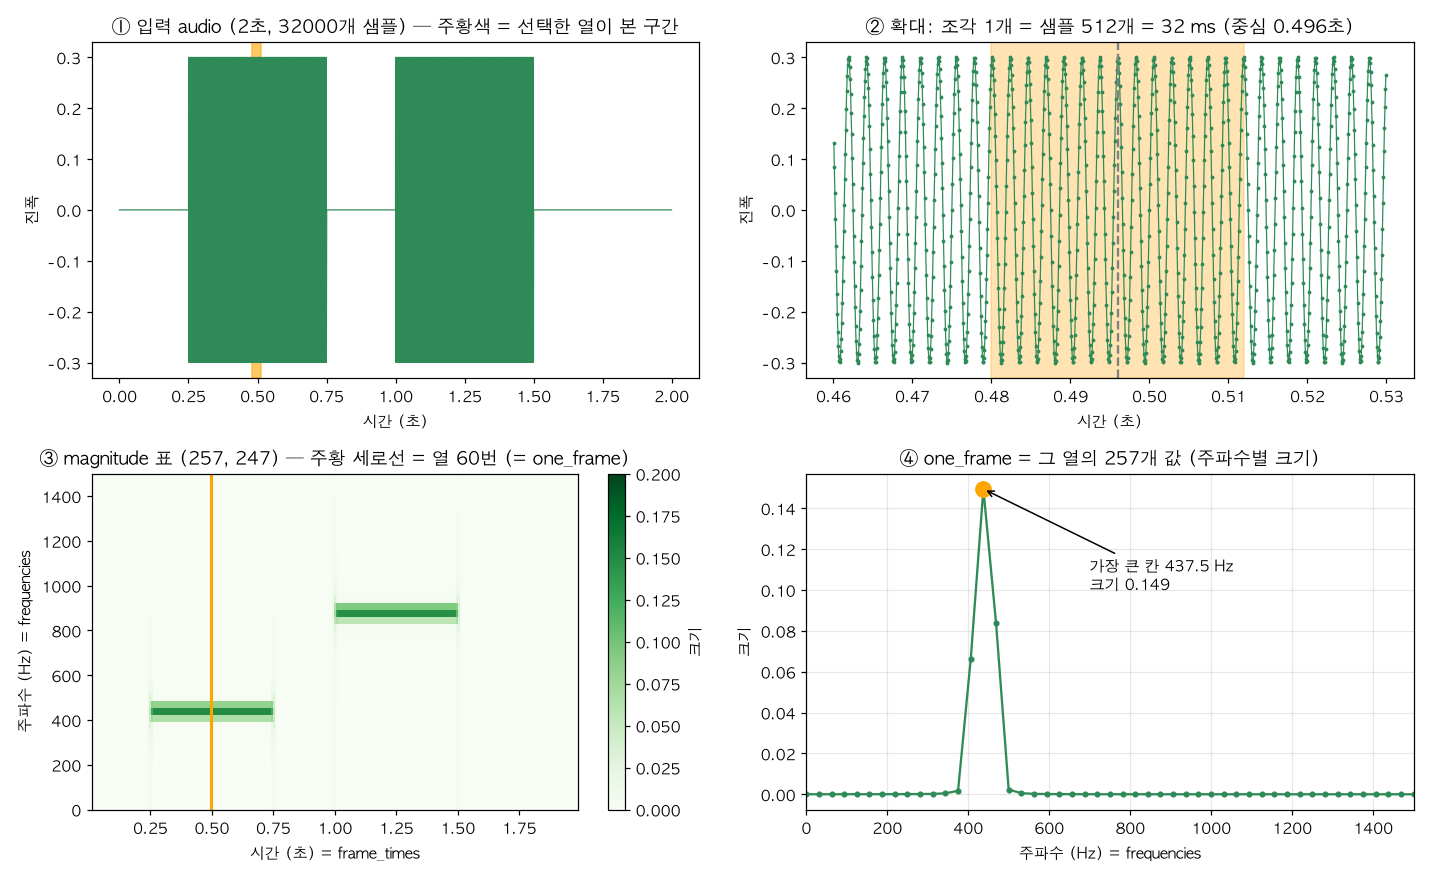

In [ ]:
# 마지막 코드 셀이 하는 일을 "그림 4장"으로 보기
# (이 셀은 앞의 compute_stft, audio, sr 변수를 그대로 사용합니다.)
frequencies, frame_times, spectrum = compute_stft(audio, sr, 512, 128)
magnitude = np.abs(spectrum)
selected_column = int(np.argmin(np.abs(frame_times - 0.5)))
one_frame = magnitude[:, selected_column]

center = frame_times[selected_column]                  # 0.496초: 이 열을 만든 조각의 중심 시각
start_sample = selected_column * 128                   # 그 조각의 첫 샘플 번호 (열 번호 × hop)
win_start, win_end = start_sample / sr, (start_sample + 512) / sr   # 조각이 차지하는 시간 구간(초)

fig, axes = plt.subplots(2, 2, figsize=(13, 8))

# ① 입력: 전체 파형 (audio) 위에 이 열이 "본 구간"을 표시
t_audio = np.arange(len(audio)) / sr
axes[0, 0].plot(t_audio, audio, color="seagreen", linewidth=0.8)
axes[0, 0].axvspan(win_start, win_end, color="orange", alpha=0.6)
axes[0, 0].set(title="① 입력 audio (2초, 32000개 샘플) — 주황색 = 선택한 열이 본 구간", xlabel="시간 (초)", ylabel="진폭")

# ② 그 구간을 확대: 512개 샘플 = 32 ms
zoom = (t_audio > 0.46) & (t_audio < 0.53)
axes[0, 1].plot(t_audio[zoom], audio[zoom], color="seagreen", marker=".", markersize=3, linewidth=0.8)
axes[0, 1].axvspan(win_start, win_end, color="orange", alpha=0.3)
axes[0, 1].axvline(center, color="gray", linestyle="--")
axes[0, 1].set(title=f"② 확대: 조각 1개 = 샘플 512개 = 32 ms (중심 {center:.3f}초)", xlabel="시간 (초)", ylabel="진폭")

# ③ STFT 표(magnitude): 세로 = frequencies, 가로 = frame_times, 색 = 크기. 선택한 열을 세로선으로 표시
mesh = axes[1, 0].pcolormesh(frame_times, frequencies, magnitude, shading="auto", cmap="Greens", vmin=0, vmax=0.2)
axes[1, 0].axvline(center, color="orange", linewidth=2)
axes[1, 0].set(title=f"③ magnitude 표 {magnitude.shape} — 주황 세로선 = 열 {selected_column}번 (= one_frame)",
               xlabel="시간 (초) = frame_times", ylabel="주파수 (Hz) = frequencies", ylim=(0, 1500))
fig.colorbar(mesh, ax=axes[1, 0], label="크기")

# ④ 그 열 하나(one_frame)를 펼쳐 보기: 주파수별 크기
axes[1, 1].plot(frequencies, one_frame, color="seagreen", marker=".")
peak_index = int(np.argmax(one_frame))
axes[1, 1].plot(frequencies[peak_index], one_frame[peak_index], "o", color="orange", markersize=10)
axes[1, 1].annotate(f"가장 큰 칸 {frequencies[peak_index]} Hz\n크기 {one_frame[peak_index]:.3f}",
                    (frequencies[peak_index], one_frame[peak_index]), xytext=(700, 0.10),
                    arrowprops=dict(arrowstyle="->"))
axes[1, 1].set(title=f"④ one_frame = 그 열의 {one_frame.shape[0]}개 값 (주파수별 크기)", xlabel="주파수 (Hz) = frequencies", ylabel="크기", xlim=(0, 1500))
axes[1, 1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

print("조각의 첫 샘플 번호:", start_sample, "/ 마지막 샘플 번호:", start_sample + 511)
print("조각의 시간 구간: %.3f ~ %.3f초 / 중심 %.3f초" % (win_start, win_end, center))
print("frequencies[14] =", frequencies[14], "Hz  (칸 번호 × 31.25)")


#### 3. 그림 4장과 코드 줄의 대응
| 그림 | 보여 주는 것 | 해당 코드 |
|---|---|---|
| **①** 전체 파형 + 주황 띠 | 입력 소리 `audio`와, 선택한 열이 **실제로 본 구간** | `audio`, 열 번호 × hop |
| **②** 주황 구간 확대 | 그 구간은 **샘플 512개 = 32 ms**. 440 Hz 사인파가 이 안에 약 14번 오르내림 | `compute_stft(audio, sr, 512, 128)`의 `512` |
| **③** `magnitude` 표 + 주황 세로선 | 표 전체. 세로선 하나가 **`selected_column`** (60번 열) | `selected_column = argmin(abs(frame_times - 0.5))` |
| **④** `one_frame` 그래프 | 그 세로선 한 줄을 **옆으로 펼친 것**. 437.5 Hz에서 가장 큼 | `one_frame = magnitude[:, selected_column]`, `argmax` |

- **①→②:** 열 하나는 소리 전체가 아니라 **짧은 조각 512개**만 보고 만든 값입니다. 조각의 위치는 `열 번호 × hop = 60 × 128 = 7680번 샘플`부터이고, 시간으로는 `0.480 ~ 0.512초`, **중심이 0.496초**입니다(코드 출력 `선택한 프레임 중심: 0.496 초`).
- **②→④:** 이 512개 샘플을 FFT한 결과가 **③의 세로선 한 줄 = ④의 그래프**입니다. 앞에서 한 구간 FFT(`rfft` → `abs`)와 **같은 계산**입니다. STFT는 이것을 **hop(128샘플)씩 옮겨 가며 247번** 반복해서 가로로 이어 붙인 표입니다.
- **③→④:** 표를 세로선으로 자르면 그 단면이 ④입니다. ③의 440 Hz 띠 한가운데를 지나는 선이라서 ④에서 400~500 Hz 부근에 봉우리가 하나 있습니다.

#### 4. 헷갈리기 쉬운 부분 풀이
- **왜 0.5초가 아니라 `0.496초`인가?** 열의 시각은 **0.016초부터 0.008초(= hop 128 ÷ 16000)** 간격이라 `0.496`과 `0.504`는 있어도 정확히 `0.5`는 없습니다. 그래서 `np.argmin(np.abs(frame_times - 0.5))`로 **"0.5와 차이가 가장 작은 열"** 을 찾습니다(`frame_times - 0.5`의 절댓값이 가장 작은 위치의 번호).
- **`magnitude[:, selected_column]`** 의 `:`는 "모든 행"입니다. 즉 **60번 열의 모든 주파수 칸 257개**를 꺼냅니다(`one_frame.shape = (257,)`).
- **`np.argmax(one_frame)`는 "값"이 아니라 "번호"를 돌려줍니다.** 가장 큰 칸의 번호가 `14`이고, 그 번호를 `frequencies[14]`에 넣어야 `437.5 Hz`(= `14 × 31.25`)가 나옵니다. (`one_frame.max()`는 크기 `0.149` 자체입니다.)
- **왜 `440`이 아니라 `437.5 Hz`인가?** 주파수 칸이 `31.25 Hz` 간격(`SR ÷ 512`)이라서, 440 Hz에 가장 가까운 칸이 `437.5`입니다. 칸 사이의 값은 표현하지 못합니다(앞의 "칸 간격 = SR ÷ N" 규칙).
- **`audio`, `spectrum`, `magnitude`의 차이:** `audio`는 시간 순서로 늘어선 **샘플들**, `spectrum`은 시간×주파수 **복소수 표**, `magnitude`는 그 표에서 **크기만** 남긴 것입니다.

#### 5. 이 셀이 보여 주는 것 (한 줄)
- STFT 표에서 **"특정 시각 하나"를 고르면 그 순간의 주파수 분포 한 줄**이 나오고, 거기서 **가장 센 주파수**를 읽을 수 있습니다. 앞 셀의 `0.5초: 437.5 Hz / 1.2초: 875.0 Hz`와 같은 방식입니다. FFT는 "언제"를 몰랐는데, STFT는 **"이 시각에는 이 주파수가 센다"** 를 읽을 수 있다는 점이 오늘 배운 차이입니다.


# 2026.10.23(금) 22h~

In [33]:
# 세 그래프가 모두 동일한 실제 음성 데이터를 사용하도록 재계산
time = np.arange(len(audio)) / sr

# 전체 FFT: 실제 audio의 주파수별 크기와 Hz 축
fft_result = np.fft.rfft(audio)
fft_size = np.abs(fft_result) / len(audio)
frequency_axis = np.fft.rfftfreq(len(audio), d=1 / sr)

# STFT: 동일한 audio를 짧은 구간마다 분석
frequencies, frame_times, spectrum = compute_stft(audio, sr, 512, 128)
magnitude = np.abs(spectrum)

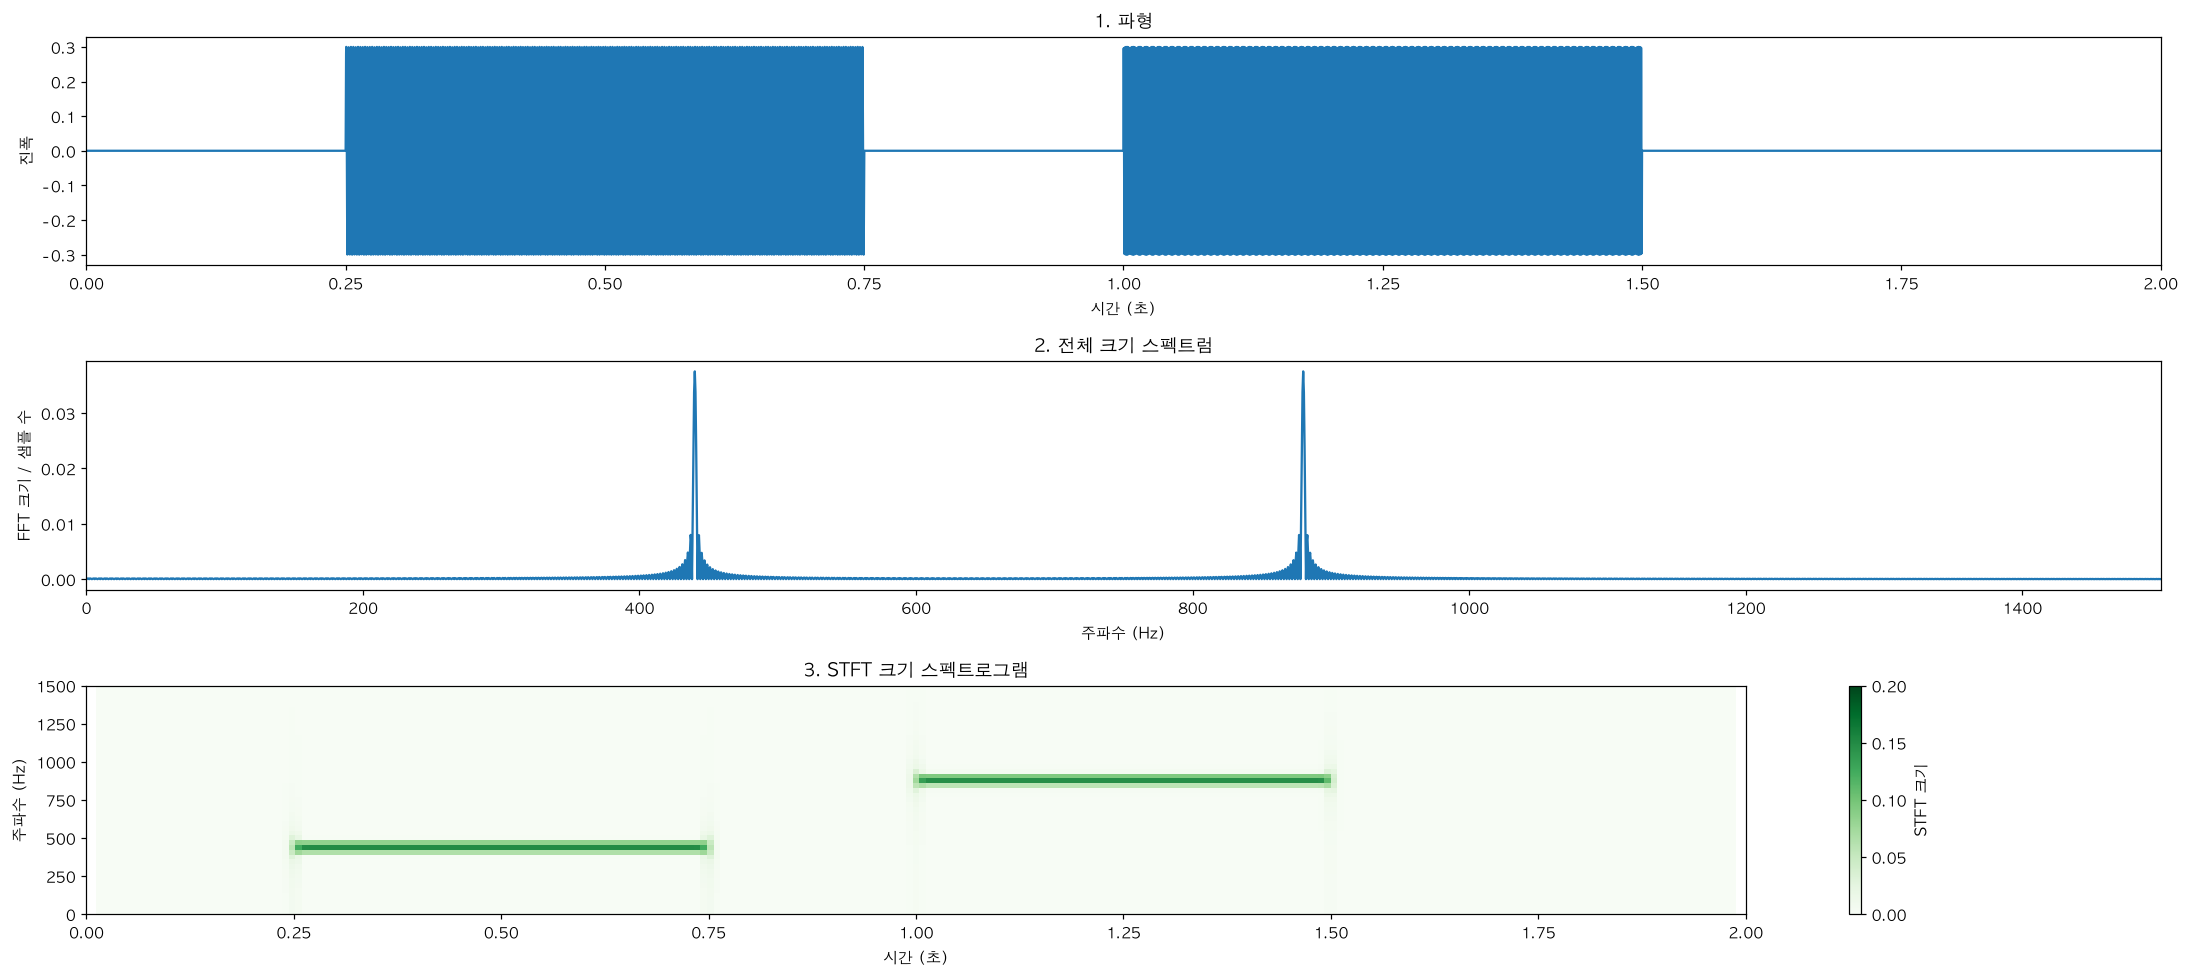

In [ ]:
fig, axes = plt.subplots(3, 1, figsize=(20, 9))

axes[0].plot(time, audio) # 각각 x/y축
axes[0].set(title="1. 파형", xlabel="시간 (초)", ylabel="진폭", xlim=(0, 2)) # 쌩 소리 (숫자로 그린) 그래프

axes[1].plot(frequency_axis, fft_size) # 각각 x/y축
axes[1].set(title="2. 전체 크기 스펙트럼", xlabel="주파수 (Hz)",
            ylabel="FFT 크기 / 샘플 수", xlim=(0, 1500))

mesh = axes[2].pcolormesh(frame_times, frequencies, magnitude, # 각각 x/y축, x/y축에 해당하는 값들..
                          shading="auto", cmap="Greens", vmin=0, vmax=0.2)
axes[2].set(title="3. STFT 크기 스펙트로그램", xlabel="시간 (초)",
            ylabel="주파수 (Hz)", xlim=(0, 2), ylim=(0, 1500))
fig.colorbar(mesh, ax=axes[2], label="STFT 크기")

plt.tight_layout()

RESULT_DIR = Path("results")
RESULT_DIR.mkdir(exist_ok=True)
figure_path = RESULT_DIR / "lesson03_three_views.png"
fig.savefig(figure_path, dpi=140, bbox_inches="tight")
plt.show()

# 22h15~

## 실제 음성 실습 — 내 목소리를 파형·FFT·STFT로 비교하기

앞에서는 **440Hz와 880Hz를 미리 알고 있는 합성음**으로 FFT와 STFT의 원리를 확인했습니다.  
이제 2강에서 사용한 " **my_voice.wav** "를 이용하여 실제 음성을 분석합니다.

실제 사람의 목소리는 하나의 주파수로 이루어져 있지 않습니다.  
시간에 따라 여러 주파수 성분의 크기가 계속 달라지므로 합성음보다 훨씬 복잡한 모양이 나타납니다.

이번 실습에서는 같은 음성을 세 가지 방법으로 살펴봅니다.

```text
실제 음성 my_voice.wav
        ↓
16kHz · 모노로 전처리
        ↓
 ┌────────────┬────────────┬────────────┐
 │   파형     │ 전체 FFT   │    STFT    │
 │ 언제 소리가 │ 어떤 주파수│  어떤 주파수│
 │ 있는가?    │ 가 있는가?  │  가 언제?  │
 └────────────┴────────────┴────────────┘
```

### 실습 목표

1. 실제 음성 파일의 **SR·채널·길이**를 확인합니다.
2. 스테레오 음성은 **모노**로 변환하고, 샘플링 레이트는 **16kHz로 실제 리샘플링**합니다.
3. 같은 음성을 **파형 → 전체 FFT → STFT** 순서로 비교합니다.
4. 합성음과 실제 음성의 차이를 설명합니다.

> **주의:** 샘플링 레이트 숫자만 16000으로 바꾸는 것은 리샘플링이 아닙니다.  
> `resample_poly()`를 사용하여 실제 샘플 데이터를 16kHz 기준으로 다시 계산합니다.

파일 위치는 `data/my_voice.wav` 또는 노트북과 같은 폴더의 `my_voice.wav`입니다.

In [59]:
# 1. 실제 음성 파일의 **SR·채널·길이**를 확인합니다.
VOICE_PATH = DATA_DIR / "my_voice.wav"
my_voice_path = VOICE_PATH
my_voice_sr, my_voice_source = read_pcm16(voice3_path)
my_voice_mono = (my_voice_source.mean(axis=1) if voice3_source.ndim == 2
                 else voice3_source)
print("파일명:", my_voice_path.name)
print("sampling rate:", my_voice_sr, "/ 원본 음성 모양:", my_voice_source.shape)
print("원래 음성 길이:", len(my_voice_mono) / my_voice_sr, "초")

파일명: my_voice.wav
sampling rate: 44100 / 원본 음성 모양: (351036, 2)
원래 음성 길이: 7.96 초


In [45]:
# 2. 스테레오 음성은 **모노**로 변환하고, 샘플링 레이트는 **16kHz로 실제 리샘플링**합니다.
from math import gcd
from scipy.signal import resample_poly

my_voice_target_sr = 16000

# 예상 출력 샘플 수입니다. 끝부분의 불완전한 샘플 간격은 올림합니다.
my_voice_expected_n = (len(my_voice_mono) * my_voice_target_sr + my_voice_sr - 1) // my_voice_sr
print("예상 리샘플링 샘플 수:", my_voice_expected_n)

# SR 비율을 정수로 약분합니다. 48000→24000이면 1/2입니다.
my_voice_common = gcd(my_voice_sr, my_voice_target_sr)
my_voice_up = my_voice_target_sr // my_voice_common
my_voice_down = my_voice_sr // my_voice_common
my_voice_resampled = resample_poly(my_voice_mono, up=my_voice_up, down=my_voice_down)

print("--리샘플링 결과--")
print("비율:", my_voice_up, "/", my_voice_down)
print("원본:", len(my_voice_mono), "개 /", len(my_voice_mono)/my_voice_sr, "초")
print("리샘플링:", len(my_voice_resampled), "개 /", len(my_voice_resampled)/my_voice_target_sr, "초")

예상 리샘플링 샘플 수: 127360
--리샘플링 결과--
비율: 160 / 441
원본: 351036 개 / 7.96 초
리샘플링: 127360 개 / 7.96 초


In [46]:
# 3. 같은 음성을 **파형 → 전체 FFT → STFT** 순서로 비교합니다.
time = np.arange(len(my_voice_resampled)) / my_voice_target_sr

# 전체 FFT: 실제 audio의 주파수별 크기와 Hz 축
fft_result = np.fft.rfft(my_voice_resampled)
fft_size = np.abs(fft_result) / len(my_voice_resampled)
frequency_axis = np.fft.rfftfreq(len(my_voice_resampled), d=1 / my_voice_target_sr)

# STFT: 동일한 audio를 짧은 구간마다 분석
frequencies, frame_times, spectrum = compute_stft(my_voice_resampled, my_voice_target_sr, 512, 128)
magnitude = np.abs(spectrum)

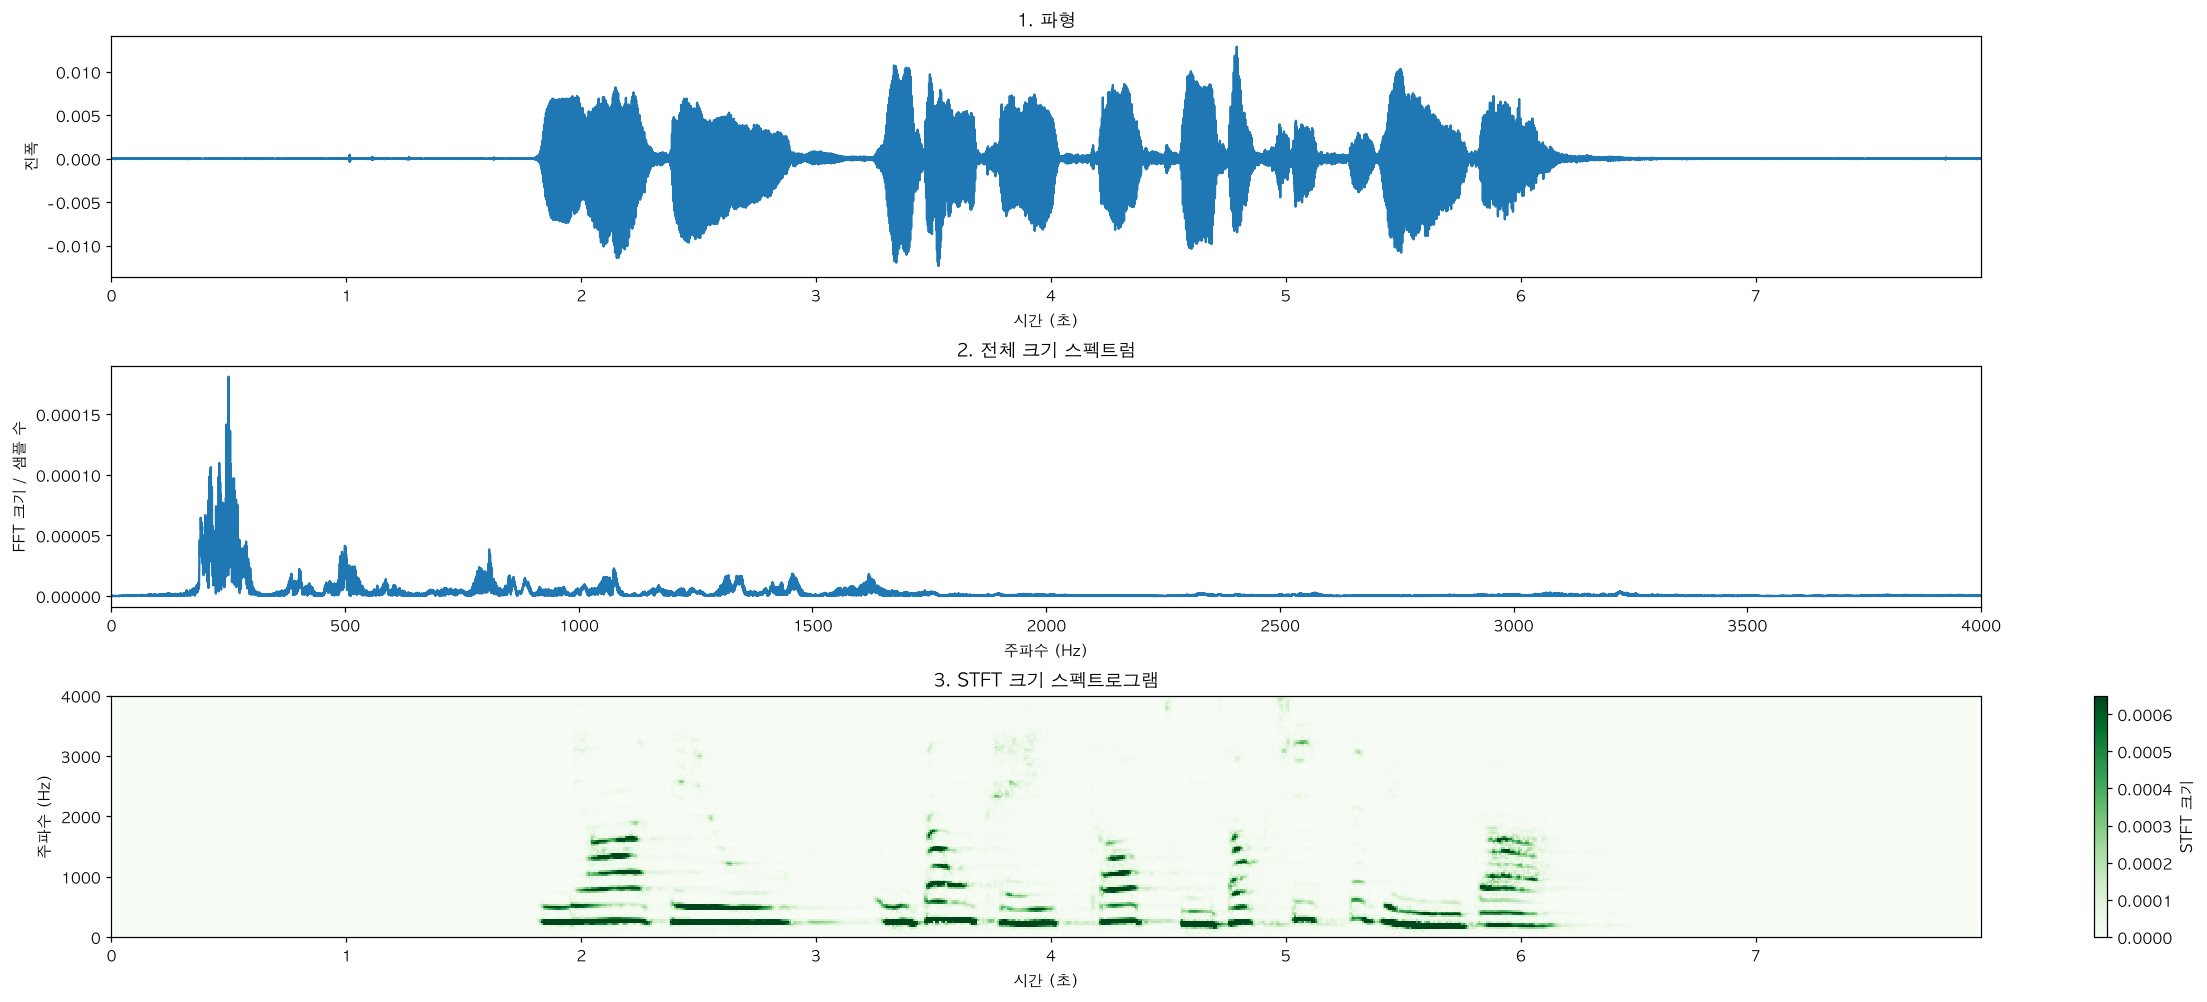

In [63]:
fig, axes = plt.subplots(3, 1, figsize=(20, 9), layout="constrained")

axes[0].plot(time, my_voice_resampled) # 각각 x/y축
axes[0].set(title="1. 파형", xlabel="시간 (초)", ylabel="진폭", xlim=(0, time[-1])) # 쌩 소리 (숫자로 그린) 그래프

axes[1].plot(frequency_axis, fft_size) # 각각 x/y축
axes[1].set(title="2. 전체 크기 스펙트럼", xlabel="주파수 (Hz)",
            ylabel="FFT 크기 / 샘플 수", xlim=(0, 4000))

mesh = axes[2].pcolormesh(frame_times, frequencies, magnitude, # 각각 x/y축, x/y축에 해당하는 값들..
                          shading="auto", cmap="Greens", vmin=0, vmax=np.percentile(magnitude, 99.5))
axes[2].set(title="3. STFT 크기 스펙트로그램", xlabel="시간 (초)",
            ylabel="주파수 (Hz)", xlim=(0, time[-1]), ylim=(0, 4000))
fig.colorbar(mesh, ax=axes[2], label="STFT 크기")

RESULT_DIR = Path("results")
RESULT_DIR.mkdir(exist_ok=True)
figure_path = RESULT_DIR / "my_voice_three_views.png"
fig.savefig(figure_path, dpi=140, bbox_inches="tight")
plt.show()

### 내 목소리 세 그림(파형·전체 FFT·STFT) 결과 평가

위 그림(`results/my_voice_three_views.png`)을 같은 녹음 데이터로 다시 계산해서 확인한 평가입니다. 추정은 (추정)으로 표시했습니다.

**총평: 결과가 좋습니다.** 세 그림이 서로 잘 맞아서, 오늘 수업의 핵심("FFT는 언제를 모르고 STFT는 안다")이 한 장에서 보입니다.

#### 1. 잘 나온 점
| 그림 | 관찰 | 근거 |
|---|---|---|
| **1. 파형** | 0~1.8초는 조용하고, **1.8~6.4초에 말소리 덩어리가 여러 개** 나뉘어 보임 | 따로 잰 말 구간(약 1.8~6.1초)과 맞음. 최대 크기 약 ±0.012로 작은 녹음 |
| **2. 전체 FFT** | **가장 센 봉우리가 약 250 Hz 부근**(192~254 Hz대에 모여 있음) | 그 뒤로 약 500, 800, 1070, 1330~1460, 1620 Hz에 작은 봉우리가 이어짐(**배음**으로 알려져 있음, 일반 지식) |
| | 2000 Hz 위는 거의 비어 있음 | 에너지의 **99.5%가 2000 Hz 아래** |
| **3. STFT** | 말소리가 있는 시간에만 줄무늬가 나타남 | 1번 파형의 소리 구간과 시간이 일치 |
| | 맨 아래 **250 Hz 띠**와 그 위로 쌓인 **배음 줄무늬** | 2번 FFT의 봉우리들과 같은 주파수 위치 |

- **세 그림의 연결:** 2번(FFT)은 250 Hz가 세다는 것만 알려 주고 **언제인지는 모릅니다.** 3번(STFT)은 같은 250 Hz 띠가 **1.8초부터 6초 사이에 끊겼다 이어졌다** 하는 모양까지 보여 줍니다. 3.3초와 4.6초 부근의 센 250 Hz 구간은 1번 파형의 큰 덩어리와도 맞습니다.

#### 2. 고치면 더 좋은 점
1. **시간축이 어긋납니다.** 색 막대가 3번째 그래프의 폭을 줄여서 **1번과 3번에서 같은 시각이 다른 위치**에 있습니다(그림에서 5초가 위쪽 그래프와 아래쪽 그래프에서 가로 위치가 다름). 이렇게 고치면 세 그래프의 가로 위치가 같아집니다(Matplotlib 3.11.2에서 확인).
   ```python
   fig, axes = plt.subplots(3, 1, figsize=(20, 9), layout="constrained")
   ...
   # plt.tight_layout() 줄은 지웁니다 (constrained와 함께 쓰지 않음)
   ```
   색 막대 줄(`fig.colorbar(mesh, ax=axes[2], ...)`)은 그대로 둬도 됩니다.
2. **3번 그림의 위쪽 줄무늬가 흐립니다.** 가장 센 한 칸(최대 약 `0.0053`)에 색 범위가 맞춰져 있어서 배음 줄무늬가 연한 색입니다. 더 또렷하게 보려면 `vmax`를 낮춥니다.
   | `vmax` | 값 | 효과 |
   |---|---|---|
   | 자동(지금) | 약 0.0053 | 가장 센 칸만 진함 |
   | `np.percentile(magnitude, 99.9)` | 약 0.002 | 배음이 더 진해짐 |
   | `np.percentile(magnitude, 99.5)` | 약 0.00065 | 아주 선명하지만 센 부분은 한 색으로 뭉침 |
3. **주파수 범위는 0~2000 Hz로 줄여도 읽기 좋습니다.** 2000 Hz 위에는 에너지가 거의 없어서 그래프 높이의 절반이 빈 칸입니다. 4000 Hz까지 보는 것도 틀린 것은 아닙니다(나이퀴스트 8000 Hz 중 일부만 표시하는 것).
4. **1.0초 부근의 작은 점**: 크기 약 `0.00045`로 말소리 최대의 3.5% 정도입니다(잡음이나 클릭 소리로 추정). 무시해도 됩니다.

#### 3. 한 줄 정리
- 내 목소리는 **약 250 Hz가 기본 높이**이고 **그 배수들이 줄무늬로 쌓이는** 모양이며, 그 줄무늬는 **말하는 시간에만** 나타납니다. 이 세 가지를 세 그림에서 각각 확인했습니다.


### 디버깅 기록 — `TypeError: only length-1 arrays can be converted to Python scalars` (`xlim=(0, int(time+1))`)

처음 실행했을 때 위 그래프 셀에서 났던 오류와 고친 과정입니다. 수치는 이 노트북의 `time`(127360개)과 같은 배열로 직접 확인했습니다.

#### 1. 오류 메시지 읽는 법
```text
Cell In[51], line 4                              ← 4번째 줄에서 났다
----> 4 axes[0].set(title="1. 파형", ..., xlim=(0, int(time+1)))   ← 문제의 줄
TypeError: only length-1 arrays can be converted to Python scalars   ← 오류 종류: 값의 "종류(타입)"가 안 맞음
```
- `TypeError` = 함수에 **잘못된 종류의 값**을 넣었다는 뜻입니다.
- 메시지 뜻: **"길이가 1인 배열만 숫자 하나로 바꿀 수 있다"** → 지금 넣은 것은 길이가 1이 아닌 배열이라서 못 바꾼다.

#### 2. 원인: `time`은 숫자 하나가 아니라 "배열"
```python
time = np.arange(len(my_voice_resampled)) / my_voice_target_sr   # 58번 셀
```
| 식 | 정체 | 모양 / 값 (직접 확인) |
|---|---|---|
| `time` | 샘플마다의 시각을 담은 **배열** | `(127360,)`, 마지막 값 `7.9599375` |
| `time + 1` | 모든 시각에 1을 더한 **배열** | `(127360,)` (여전히 배열!) |
| `int(time + 1)` | 배열 전체를 정수 **하나**로? | ❌ `TypeError` |
- `int(...)`는 **숫자 하나**를 정수로 바꾸는 함수입니다. 값이 127360개 든 배열을 넣으면 "어느 값을 바꾸라는 거지?" 하고 오류를 냅니다(`float(time)`도 같은 오류).
- 처음 의도는 아마 "**가로축을 파형 끝(약 8초)까지 보여 주자**"였을 것입니다. 그러려면 필요한 것은 **배열 전체가 아니라 "마지막 시각" 하나**입니다.

#### 3. 고치는 법: 배열에서 "값 하나"를 꺼내기
| 쓰는 방법 | 값 | 설명 |
|---|---|---|
| `time[-1]` | `7.9599375` | 배열의 **마지막 값** (가장 간단) |
| `time.max()` | `7.9599375` | 배열의 최댓값 (시간은 늘어나니 마지막과 같음) |
| `int(time[-1] + 1)` | `8` | 마지막 시각에 1을 더해 **정수로** (원래 의도에 가장 가까움) |
- 셀에는 `xlim=(0, time[-1])`로 고쳐서 쓰고 있습니다(지금 실행됨).
- 참고: **원소가 딱 1개인 배열**은 `int()`가 변환해 주지만(그래서 메시지가 "length-1 arrays만"입니다), NumPy 1.25부터는 그것도 **경고(Deprecation)** 가 나옵니다. 값 하나를 꺼내려면 `time[-1]`처럼 **인덱스로 꺼내는 습관**이 안전합니다.

#### 4. 이런 오류를 만났을 때 확인 순서 (디버깅 요령)
1. **어느 줄인지** 본다(`----> 4`).
2. 그 줄의 변수들을 **`type()`과 `.shape`** 로 찍어 본다. 이번에는 `print(type(time), time.shape)` → `<class 'numpy.ndarray'> (127360,)`이면 바로 "배열이었구나" 하고 알 수 있습니다.
3. 오류 문구 **"length-1 arrays"** 는 **"숫자 하나를 기대한 곳에 여러 개짜리 배열을 넣었다"** 의 신호입니다. `int(배열)`, `float(배열)` 등에서 자주 납니다.
4. 필요한 것이 **"배열 전체"인지 "배열 중 하나(마지막/최댓값/특정 번호)"인지** 정해서 고친다.

#### 5. 같은 셀에서 이어서 고친 것 (현재 셀 상태 확인)
- 세 번째 그래프의 `xlim=(0, 2)`는 합성음(2초) 때 값이라 내 녹음(7.96초)을 `2초`까지만 보여 줬습니다 → 지금은 `xlim=(0, time[-1])`로 고쳐져 있습니다.
- `vmax=0.2`는 내 녹음에는 너무 커서 가로 띠가 안 보였습니다(바로 아래 설명) → 지금은 `vmax`를 지워 **자동**으로 쓰고 있습니다.
- 주파수 범위도 `0~4000 Hz`로 넓혀 보고 있습니다(코드의 `xlim=(0, 4000)`, `ylim=(0, 4000)`). 표시 범위만 바꾸는 것이라 계산 결과는 그대로입니다.
- 변수 이름 `time`은 파이썬의 표준 모듈 이름(`time`)과 같습니다. 이 노트북에서는 `import time`을 쓰지 않아 지금은 문제가 없지만, 나중에 시간 측정 등으로 `time` 모듈을 쓸 때 **이름이 겹쳐 오류가 날 수 있으니** `voice_time`처럼 다른 이름이 더 안전합니다(일반 지식).


### Q. 마지막 그래프의 3번째(STFT 스펙트로그램)에 가로 띠가 안 보이는 이유와 고치는 법

**한 줄 답:** 그래프는 정상적으로 그려졌지만 **색의 범위(`vmax=0.2`)가 내 목소리에 비해 너무 커서**, 모든 칸이 "가장 연한 색"으로만 칠해진 것입니다. `vmax`를 내 데이터의 크기에 맞게 줄이면 띠가 보입니다. 아래 숫자와 그림은 이 셀의 데이터(`my_voice.wav` → 16 kHz, `compute_stft(…, 512, 128)`)로 직접 실행해서 확인했습니다.

#### 1. 왜 안 보이나
- `vmin=0, vmax=0.2`는 **"크기 0은 가장 연한 색, 크기 0.2 이상은 가장 진한 색"** 이라고 정하는 설정입니다.
- 이 설정은 **합성음용**입니다. 합성음의 STFT 최대 크기는 약 `0.149`(진폭 0.3의 절반)라서 `0.2`가 잘 맞았습니다.
- **내 녹음의 STFT 최대 크기는 `0.0053`** 입니다(합성음의 약 3% 크기). 그래서 가장 센 칸도 색 범위의 `0.0053 ÷ 0.2 = 2.6%` 지점이라, **전부 거의 흰색에 가까운 연한 색**이 됩니다. 값이 없는 것이 아니라 **색 차이가 너무 작아서 눈에 안 보이는** 것입니다.
- 내 녹음이 이렇게 작은 이유: 녹음 소리 자체가 작고(파형 최대 약 0.013), 목소리는 합성음처럼 한 주파수에 몰리지 않고 여러 주파수로 퍼져 있어서 한 칸의 값이 더 작습니다(추정). 앞의 "색 막대 숫자" 설명에서 예고한 상황입니다.

#### 2. 세 가지 설정을 나란히 비교 (아래 코드 셀)


magnitude 최댓값: 0.0053
0~2000 Hz 범위의 최댓값: 0.0053
현재 vmax=0.2 → 최댓값의 2.6% 밝기까지만 올라감 (거의 가장 연한 색)


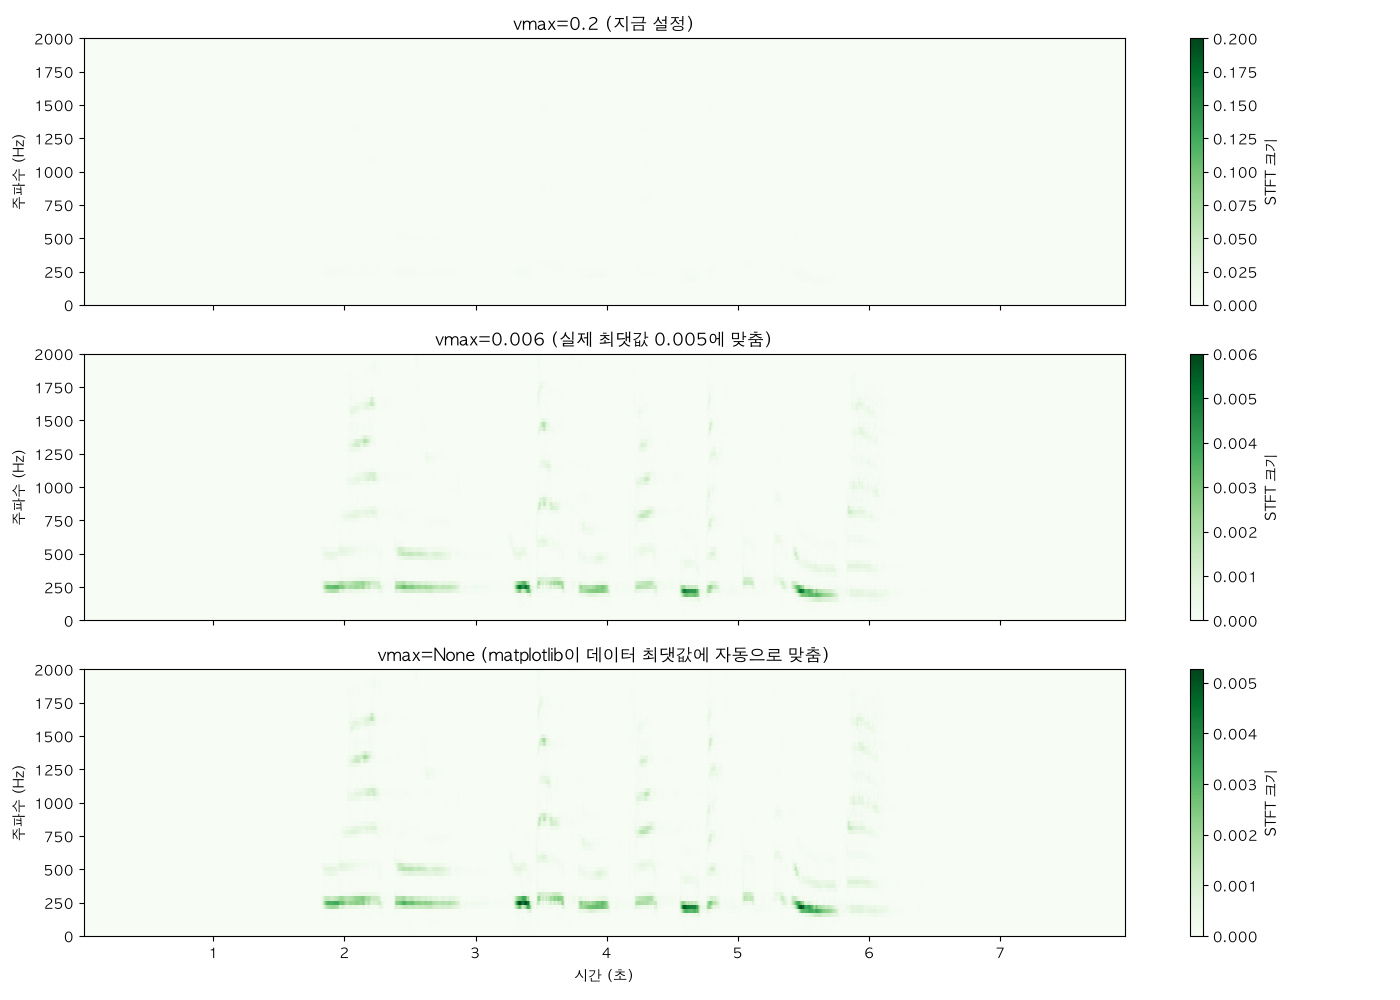

In [ ]:
# 스펙트로그램의 "가로 띠"가 안 보이는 이유: vmax(색의 최댓값)와 실제 크기의 불일치
print("magnitude 최댓값:", round(float(magnitude.max()), 4))
print("0~2000 Hz 범위의 최댓값:", round(float(magnitude[frequencies <= 2000].max()), 4))
print("현재 vmax=0.2 → 최댓값의 %.1f%% 밝기까지만 올라감 (거의 가장 연한 색)" % (100 * magnitude.max() / 0.2))

fig, axes = plt.subplots(3, 1, figsize=(14, 10), sharex=True)
settings = [("vmax=0.2 (지금 설정)", 0.2),
            ("vmax=0.006 (실제 최댓값 0.005에 맞춤)", 0.006),
            ("vmax=None (matplotlib이 데이터 최댓값에 자동으로 맞춤)", None)]
for ax, (title, vmax) in zip(axes, settings):
    mesh = ax.pcolormesh(frame_times, frequencies, magnitude,
                         shading="auto", cmap="Greens", vmin=0, vmax=vmax)
    ax.set(title=title, ylabel="주파수 (Hz)", ylim=(0, 2000))
    fig.colorbar(mesh, ax=ax, label="STFT 크기")
axes[-1].set_xlabel("시간 (초)")
plt.tight_layout()
plt.show()


> ※ 위 비교 그림 셀의 "vmax=0.2 (지금 설정)"은 **수정 전** 설정을 말합니다. 현재 그래프 셀은 이미 `vmax`를 지워(자동) 고친 상태입니다.

#### 3. 어떻게 고치나
고칠 곳은 **3번째 그래프의 `vmax` 한 군데**입니다.
```python
mesh = axes[2].pcolormesh(frame_times, frequencies, magnitude,
                          shading="auto", cmap="Greens", vmin=0, vmax=0.006)   # 0.2 → 0.006
```
| 선택지 | 코드 | 특징 |
|---|---|---|
| **직접 값 지정** | `vmax=0.006` | 실제 최댓값(`0.0053`)보다 약간 크게 → 가장 센 칸이 진한 초록. 두 번째 그림 |
| **자동** | `vmax=None` (또는 `vmax` 줄을 지움) | matplotlib이 데이터 최댓값에 알아서 맞춤. 세 번째 그림. 편하지만 **데이터마다 색의 기준이 달라집니다** |
| 더 쨍하게(선택) | `vmax=np.percentile(magnitude, 99.5)` | 가장 센 0.5% 칸을 빼고 맞춤(이 데이터에서 약 `0.00065`). 약한 소리까지 진하게 보이지만 센 부분은 한 색으로 뭉침 |

- **두 소리를 비교할 때**(예: 합성음 vs 내 목소리)는 **같은 `vmax`를 써야** 색이 같은 크기를 뜻합니다. 각각 자동(`None`)으로 하면 색 막대 숫자가 달라서 그림만 보고 크기를 비교하면 틀릴 수 있습니다.
- 수정 후에도 `vmin=0`은 그대로 둡니다(크기는 0 이상이라 가장 연한 색이 0).

#### 4. 고친 그림에서 읽을 수 있는 것
- **아래쪽(약 250 Hz) 진한 가로 띠**: 목소리에서 가장 센 주파수 부근입니다. 앞에서 전체 FFT로 구한 가장 센 주파수(약 250 Hz)와 같은 위치입니다.
- **그 위로 여러 개의 가로 줄이** 일정한 간격으로 쌓여 있습니다.** 2.2초 부근 한 열에서 봉우리를 찾으니 대략 `281 / 812 / 1094 / 1344 / 1625 Hz`였고, 약 270 Hz 간격으로 겹겹이 나타납니다. 사람 목소리는 기본 주파수의 배수들이 함께 나오는 성질(배음)이 있어서 이런 줄무늬로 보인다고 알려져 있습니다(일반 지식, 이 노트북에서 증명하지 않음).
- **세로로 비어 있는 곳**(약 1.0~1.8초, 6.5초 이후)은 소리가 없는 구간(말 시작 전·끝난 후)입니다. 파형 그래프의 조용한 구간과 시간이 맞습니다.
- FFT(2번째 그래프)는 이 줄무늬가 **언제** 나왔는지 몰랐지만, STFT는 **시간에 따라 음의 높이가 변하는 모양**까지 보여 줍니다.

#### 5. 흔한 함정 정리 (★)
- **`vmax`는 "계산 결과"가 아니라 "표시 범위"입니다.** 데이터가 바뀌면(합성음 → 내 목소리, 다른 녹음 크기) 다시 맞춰야 합니다.
- **그래프가 비어 보인다 = 값이 0이다가 아닙니다.** 색 범위와 실제 값의 크기가 안 맞는지 먼저 의심하세요. `magnitude.max()`를 찍어 보면 바로 알 수 있습니다.
- 3번째 그래프의 `ylim=(0, 2000)`과 `xlim=(0, time[-1])`은 지금 내 데이터에 맞게 잘 바뀌어 있습니다.


### 부연 — 줄무늬 선명도는 `vmax`(퍼센타일)로 정해집니다: 99.9 vs 99.5

`vmax=np.percentile(magnitude, 99.9)`와 `99.5`로 바꿔 그려 본 결과를 정리합니다. 수치는 이 녹음의 STFT 표(257 × 992칸 = 254,944칸)로 직접 계산했습니다.

#### 1. `np.percentile(magnitude, 99.5)`가 뜻하는 것
- 표의 **모든 칸의 크기를 작은 것부터 줄 세웠을 때 99.5% 위치의 값**입니다.
- 그래서 **칸의 0.5%는 이 값보다 크고**, 그 칸들은 모두 **가장 진한 초록(색의 끝)** 으로 칠해집니다(`vmax` 이상은 같은 색).
- 즉 `vmax`는 "계산 결과"가 아니라 **"어디까지를 서로 다른 색으로 구분해 보여 줄까"를 정하는 표시 범위**입니다.

#### 2. 설정별로 비교 (직접 계산)
| `vmax` 설정 | 값 | 실제 최댓값(0.0053) 대비 | 가장 진한 색으로 뭉치는 칸 | 약한 소리를 보여 주는 정도 |
|---|---|---|---|---|
| 자동(`None`) | 0.0053 | 100% | 0% | 가장 약함 (연한 색에 묻힘) |
| 99.9 퍼센타일 | 0.0021 | 39% | 0.1% | 중간 |
| **99.5 퍼센타일** | **0.00065** | **12%** | **0.5%** | **좋음** |
| 99 퍼센타일 | 0.00029 | 5% | 1.0% | 더 좋음, 뭉침도 커짐 |

- 같은 데이터에서 **"크기가 `vmax`의 5% 이상이라 색이 눈에 띄게 오르는 칸"의 비율**은 자동 `1.1%`, 99.9 `2.0%`, **99.5 `4.4%`**, 99 `7.6%`입니다. 자동에서 99.5로 바꾸면 **눈에 보이는 칸이 4배로** 늘어납니다.

#### 3. 실제 그림에서 보인 차이
- **99.9**: 250 Hz 띠와 아래쪽 배음 줄무늬가 또렷해졌습니다.
- **99.5**: 배음 줄무늬가 더 선명해졌고, **3000 Hz 부근의 희미한 무늬**(2.5~3.8초, 5초 부근)까지 보입니다.
- 두 경우 모두 1번 파형의 소리 구간과 시간이 일치하고, 소리가 없는 구간(약 0~1.8초, 6.5초 이후)은 연한 색 그대로입니다.

#### 4. 왜 이렇게 `vmax`를 낮춰야 선명해지나
- 소리의 STFT 표는 **대부분의 칸이 0에 가깝고, 소수의 칸만 큽니다.** 이 녹음에서는 `vmax`의 5% 이상인 칸이 자동 설정에서 **1.1%** 뿐입니다.
- 자동(`None`)은 **가장 센 한두 칸**에 색 범위를 맞추므로, 나머지 줄무늬는 전부 연한 색에 가깝게 눌립니다.
- 퍼센타일은 "가장 센 몇 칸은 포기하고(뭉치게 두고) 나머지를 잘 보이게" 하는 방법입니다.

#### 5. 주의할 점 (★)
- **가장 진한 칸은 서로 구분되지 않습니다.** 99.5에서는 칸의 0.5%가 같은 가장 진한 색입니다. 그 안에서 "어느 것이 더 센가"는 이 그림으로 알 수 없습니다.
- **색 막대의 최댓값(0.00065)은 실제 최댓값이 아닙니다.** 막대 위쪽 숫자를 "전체 범위의 끝"으로 읽으면 안 됩니다(실제 최댓값은 0.0053).
- **두 소리를 비교할 때는 같은 `vmax`를 써야** 색이 같은 크기를 뜻합니다. 각각 퍼센타일로 정하면 막대 숫자가 달라서 색만 보고 크기를 비교할 수 없습니다.
- 퍼센타일 값은 **데이터마다 달라집니다.** 같은 코드를 합성음에 쓰면 `vmax`도 달라집니다.

#### 6. 무엇을 보고 싶은지에 따라 고르기
| 목적 | 추천 설정 |
|---|---|
| **줄무늬(배음 모양, 시간에 따른 변화)** 를 보고 싶다 | **99.5** (이 그림에서 가장 보기 좋음) |
| **센 정도의 차이**까지 보고 싶다 | 99.9 또는 자동(`None`) |
| 두 소리를 **공평하게 비교**하고 싶다 | 두 소리에 같은 `vmax`를 직접 지정 (예: `vmax=0.002`) |
| 소리의 크기 차이가 아주 큰 데이터 | 로그(dB) 눈금도 흔히 씀(일반 지식, 이 노트북에서는 쓰지 않음) |
